# Custom OCR on Lab Reports — YOLOv3 + Tesseract
**Objective:** Detect specific regions in Thyrocare lab report images using a custom-trained YOLOv3 model, crop those regions, and extract structured text via Tesseract OCR. Output is saved as a CSV.

**Pipeline:**
```
Lab Report Image → YOLOv3 Detection → Crop Regions → Tesseract OCR → Structured CSV
```

**Sections:**
1. Environment Setup
2. Data Loading & Cleanup
3. Missing Value Handling
4. Univariate Analysis
5. Bivariate Analysis
6. Multivariate Analysis
7. Outlier Detection & Handling
8. YOLO Dataset Preparation & Annotation
9. YOLOv3 Training
10. Inference + OCR Pipeline
11. Post-processing & CSV Output
12. Evaluation & Reporting
13. Evaluation & Optimization (Req §5)
14. Automation & Deployment (Req §6)
15. Documentation & Final Report (Req §7)

## Section 1 — Environment Setup

In [1]:
# Install system-level Tesseract OCR engine
import subprocess, sys

def install(pkg):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

# Detect environment
try:
    import google.colab
    IN_COLAB = True
    print('Running in Google Colab')
    !apt-get install -y tesseract-ocr tesseract-ocr-eng > /dev/null 2>&1
    !apt-get install -y libgl1-mesa-glx > /dev/null 2>&1
except ImportError:
    IN_COLAB = False
    print('Running locally — ensure Tesseract is installed: https://github.com/UB-Mannheim/tesseract/wiki')

for pkg in ['pytesseract', 'opencv-python-headless', 'Pillow',
            'matplotlib', 'seaborn', 'pandas', 'numpy',
            'scikit-learn', 'tqdm', 'scipy']:
    install(pkg)

print('All dependencies installed.')

Running locally — ensure Tesseract is installed: https://github.com/UB-Mannheim/tesseract/wiki
All dependencies installed.


In [2]:
import os, shutil, cv2, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import pytesseract
from PIL import Image
from pathlib import Path
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 110

# ── Tesseract path (Windows local) ────────────────────────────────────────────
if not IN_COLAB:
    pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files\Tesseract-OCR\tesseract.exe'

print('Libraries imported successfully.')

Libraries imported successfully.


In [3]:
# ── Mount Google Drive (Colab only) ───────────────────────────────────────────
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = '/content/drive/MyDrive/OCR_LabReport'
else:
    DRIVE_ROOT = r'C:\Users\ecsbb\OneDrive\Desktop\Sarita_AIML_Sessions\NextHikesInternship\Project10'

# ── Project folder structure ───────────────────────────────────────────────────
CFG = {
    'dataset_dir'   : os.path.join(DRIVE_ROOT, 'drive-download-20261013T185652Z-1-001'),
    'output_dir'    : os.path.join(DRIVE_ROOT, 'output'),
    'yolo_dir'      : os.path.join(DRIVE_ROOT, 'yolo_dataset'),
    'model_dir'     : os.path.join(DRIVE_ROOT, 'model'),
    'results_dir'   : os.path.join(DRIVE_ROOT, 'results'),
    'crop_dir'      : os.path.join(DRIVE_ROOT, 'crops'),
    'img_size'      : 416,
    'num_classes'   : 1,
    'class_names'   : ['lab_data_region'],
    'train_split'   : 0.8,
    'val_split'     : 0.1,
    'test_split'    : 0.1,
    'conf_threshold': 0.5,
    'nms_threshold' : 0.4,
    'random_seed'   : 42,
}

for d in ['output_dir', 'yolo_dir', 'model_dir', 'results_dir', 'crop_dir']:
    os.makedirs(CFG[d], exist_ok=True)
    os.makedirs(os.path.join(CFG['yolo_dir'], 'images', 'train'), exist_ok=True)
    os.makedirs(os.path.join(CFG['yolo_dir'], 'images', 'val'),   exist_ok=True)
    os.makedirs(os.path.join(CFG['yolo_dir'], 'images', 'test'),  exist_ok=True)
    os.makedirs(os.path.join(CFG['yolo_dir'], 'labels', 'train'), exist_ok=True)
    os.makedirs(os.path.join(CFG['yolo_dir'], 'labels', 'val'),   exist_ok=True)
    os.makedirs(os.path.join(CFG['yolo_dir'], 'labels', 'test'),  exist_ok=True)

print('Folder structure created.')
print(json.dumps({k: v for k, v in CFG.items() if '_dir' in k}, indent=2))

Folder structure created.
{
  "dataset_dir": "C:\\Users\\ecsbb\\OneDrive\\Desktop\\Sarita_AIML_Sessions\\NextHikesInternship\\Project10\\drive-download-20261013T185652Z-1-001",
  "output_dir": "C:\\Users\\ecsbb\\OneDrive\\Desktop\\Sarita_AIML_Sessions\\NextHikesInternship\\Project10\\output",
  "yolo_dir": "C:\\Users\\ecsbb\\OneDrive\\Desktop\\Sarita_AIML_Sessions\\NextHikesInternship\\Project10\\yolo_dataset",
  "model_dir": "C:\\Users\\ecsbb\\OneDrive\\Desktop\\Sarita_AIML_Sessions\\NextHikesInternship\\Project10\\model",
  "results_dir": "C:\\Users\\ecsbb\\OneDrive\\Desktop\\Sarita_AIML_Sessions\\NextHikesInternship\\Project10\\results",
  "crop_dir": "C:\\Users\\ecsbb\\OneDrive\\Desktop\\Sarita_AIML_Sessions\\NextHikesInternship\\Project10\\crops"
}


## Section 2 — Data Loading & Cleanup

In [4]:
# ── Load all image paths ───────────────────────────────────────────────────────
all_paths = sorted(Path(CFG['dataset_dir']).glob('*.jpg'))
print(f'Total images found: {len(all_paths)}')
print(f'Sample filenames: {[p.name for p in all_paths[:5]]}')

Total images found: 100
Sample filenames: ['thyrocare_0_1001.jpg', 'thyrocare_0_1174.jpg', 'thyrocare_0_122.jpg', 'thyrocare_0_123.jpg', 'thyrocare_0_1248.jpg']


In [5]:
# ── Data Cleanup: detect corrupt / unreadable images ──────────────────────────
records = []
corrupt_images = []

for path in tqdm(all_paths, desc='Scanning images'):
    record = {
        'filename'   : path.name,
        'filepath'   : str(path),
        'file_size_kb': round(path.stat().st_size / 1024, 2),
        'readable'   : False,
        'width'      : None,
        'height'     : None,
        'channels'   : None,
        'aspect_ratio': None,
        'mean_r'     : None,
        'mean_g'     : None,
        'mean_b'     : None,
        'std_r'      : None,
        'std_g'      : None,
        'std_b'      : None,
        'brightness' : None,
        'contrast'   : None,
        'sharpness'  : None,
        'class_label': int(path.stem.split('_')[1]) if '_' in path.stem else 0,
    }
    try:
        img = cv2.imread(str(path))
        if img is None:
            raise ValueError('cv2.imread returned None')
        pil_img = Image.open(str(path))
        pil_img.verify()  # verify integrity

        h, w, c = img.shape
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        b, g, r = cv2.split(img)
        lap_var = cv2.Laplacian(gray, cv2.CV_64F).var()

        record.update({
            'readable'    : True,
            'width'       : w,
            'height'      : h,
            'channels'    : c,
            'aspect_ratio': round(w / h, 4),
            'mean_r'      : round(float(r.mean()), 4),
            'mean_g'      : round(float(g.mean()), 4),
            'mean_b'      : round(float(b.mean()), 4),
            'std_r'       : round(float(r.std()),  4),
            'std_g'       : round(float(g.std()),  4),
            'std_b'       : round(float(b.std()),  4),
            'brightness'  : round(float(gray.mean()), 4),
            'contrast'    : round(float(gray.std()),  4),
            'sharpness'   : round(lap_var, 4),
        })
    except Exception as e:
        corrupt_images.append({'filename': path.name, 'error': str(e)})

    records.append(record)

df = pd.DataFrame(records)
#print(f'\nReadable  : {df["readable"].sum()}')
#print(f'Corrupt   : {(~df["readable"]).sum()}')
if corrupt_images:
    print('Corrupt files:', [c["filename"] for c in corrupt_images])

Scanning images: 100%|██████████| 100/100 [00:06<00:00, 16.51it/s]


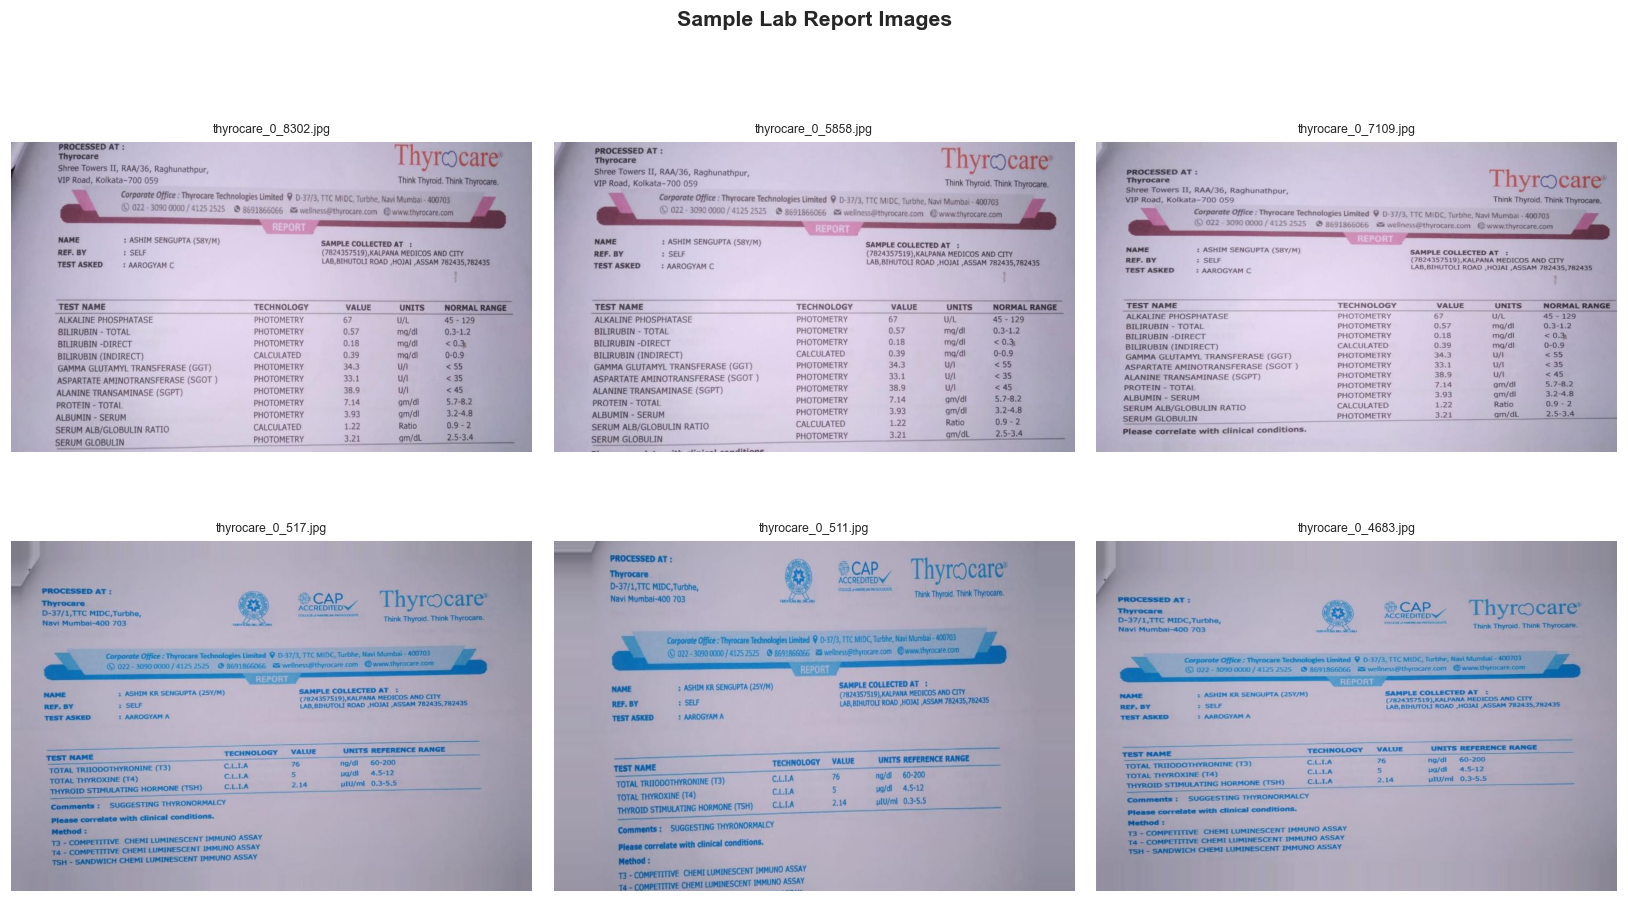

In [6]:
# ── Display sample images ──────────────────────────────────────────────────────
# Use filepath from metadata if available; otherwise fall back to raw image list
if 'filepath' in df.columns and not df.empty:
    sample_paths = df['filepath'].sample(6, random_state=42).tolist()
else:
    sample_paths = [str(p) for p in all_paths[:6]]
    if not sample_paths:
        raise FileNotFoundError(
            f"No JPG files found in dataset_dir: {CFG['dataset_dir']}. "
            "Check the folder path or run the image-scanning cells first."
        )
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, fp in zip(axes.flat, sample_paths):
    img = cv2.imread(fp)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(Path(fp).name, fontsize=8)
    ax.axis('off')
plt.suptitle('Sample Lab Report Images', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(CFG['results_dir'], 'sample_images.png'), bbox_inches='tight')
plt.show()

## Section 3 — Missing Value Handling

In [7]:
print('=== Missing Values in Image Metadata DataFrame ===')
missing_summary = df.isnull().sum()
missing_pct     = (df.isnull().sum() / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing_summary, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0]
print(missing_df if not missing_df.empty else 'No missing values in readable images.')

# Visualise missing-value map
if missing_df.shape[0] > 0:
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.heatmap(df.isnull(), cbar=False, cmap='viridis', ax=ax, yticklabels=False)
    ax.set_title('Missing Value Heatmap (yellow = missing)')
    plt.tight_layout(); plt.show()

=== Missing Values in Image Metadata DataFrame ===
No missing values in readable images.


In [8]:
# ── Strategy 1: Backfill numeric stats using column median ────────────────────
numeric_cols = ['width','height','channels','aspect_ratio','mean_r','mean_g','mean_b',
                'std_r','std_g','std_b','brightness','contrast','sharpness','file_size_kb']

# Backfill missing stats (caused by corrupt images) with column median
df_filled = df.copy()
for col in numeric_cols:
    before = df_filled[col].isnull().sum()
    df_filled[col] = df_filled[col].fillna(df_filled[col].median())
    after  = df_filled[col].isnull().sum()
    if before > 0:
        print(f'[BACKFILL] {col}: {before} NaN → filled with median ({df_filled[col].median():.2f})')

# ── Strategy 2: Drop unreadable rows if > 5% corrupt ─────────────────────────
corrupt_pct = (~df['readable']).mean() * 100
print(f'\nCorrupt image percentage: {corrupt_pct:.1f}%')

if corrupt_pct > 5:
    df_clean = df_filled[df_filled['readable']].reset_index(drop=True)
    print(f'Dropped {(~df["readable"]).sum()} corrupt rows — column drop strategy.')
else:
    df_clean = df_filled.copy()
    print('Corrupt % is low — backfill strategy used, all rows retained.')

print(f'\nFinal clean dataset shape: {df_clean.shape}')
df_clean.head(3)


Corrupt image percentage: 0.0%
Corrupt % is low — backfill strategy used, all rows retained.

Final clean dataset shape: (100, 18)


,filename,filepath,file_size_kb,readable,width,height,channels,aspect_ratio,mean_r,mean_g,mean_b,std_r,std_g,std_b,brightness,contrast,sharpness,class_label
0,thyrocare_0_1001.jpg,C:\Users\ecsbb\OneDrive\Desktop\Sarita_AIML_Se...,59.99,True,635,1043,3,0.6088,193.2098,184.9389,202.9871,23.0993,22.6966,23.2468,189.4450,22.7466,548.9067,0
1,thyrocare_0_1174.jpg,C:\Users\ecsbb\OneDrive\Desktop\Sarita_AIML_Se...,60.11,True,939,631,3,1.4881,161.5819,167.6249,192.1231,39.6229,19.8759,14.6588,168.6184,24.1910,260.0601,0
2,thyrocare_0_122.jpg,C:\Users\ecsbb\OneDrive\Desktop\Sarita_AIML_Se...,57.24,True,939,631,3,1.4881,161.9223,165.7659,188.5296,35.5139,18.5912,14.9527,167.2094,22.1838,327.6112,0


## Section 4 — Univariate Analysis

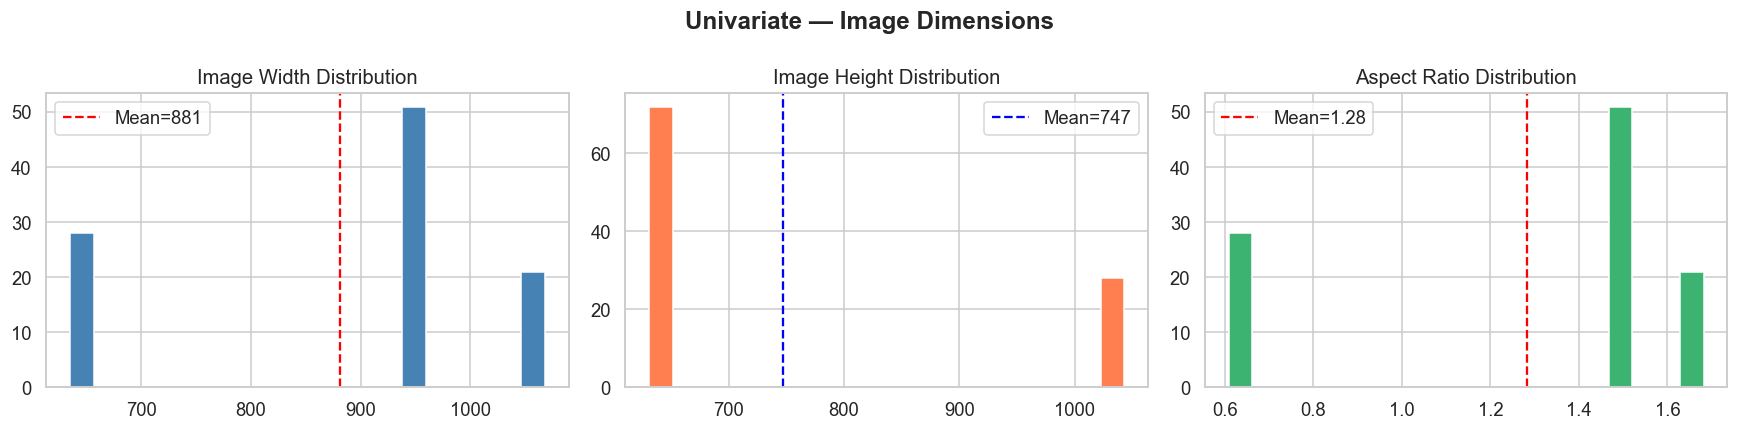

         width  height  aspect_ratio  file_size_kb
count   100.00   100.0        100.00        100.00
mean    880.97   747.2          1.28         58.98
std     162.07   185.4          0.43          6.26
min     635.00   631.0          0.61         49.25
25%     635.00   631.0          0.61         54.53
50%     939.00   631.0          1.49         57.61
75%     939.00  1043.0          1.49         61.20
max    1068.00  1043.0          1.68         74.58


In [9]:
# ── 4.1 Image Dimension Distributions ─────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(df_clean['width'], bins=20, color='steelblue', edgecolor='white')
axes[0].axvline(df_clean['width'].mean(), color='red', linestyle='--', label=f'Mean={df_clean["width"].mean():.0f}')
axes[0].set_title('Image Width Distribution'); axes[0].legend()

axes[1].hist(df_clean['height'], bins=20, color='coral', edgecolor='white')
axes[1].axvline(df_clean['height'].mean(), color='blue', linestyle='--', label=f'Mean={df_clean["height"].mean():.0f}')
axes[1].set_title('Image Height Distribution'); axes[1].legend()

axes[2].hist(df_clean['aspect_ratio'], bins=20, color='mediumseagreen', edgecolor='white')
axes[2].axvline(df_clean['aspect_ratio'].mean(), color='red', linestyle='--', label=f'Mean={df_clean["aspect_ratio"].mean():.2f}')
axes[2].set_title('Aspect Ratio Distribution'); axes[2].legend()

plt.suptitle('Univariate — Image Dimensions', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(CFG['results_dir'], 'univariate_dimensions.png'), bbox_inches='tight')
plt.show()

print(df_clean[['width','height','aspect_ratio','file_size_kb']].describe().round(2))

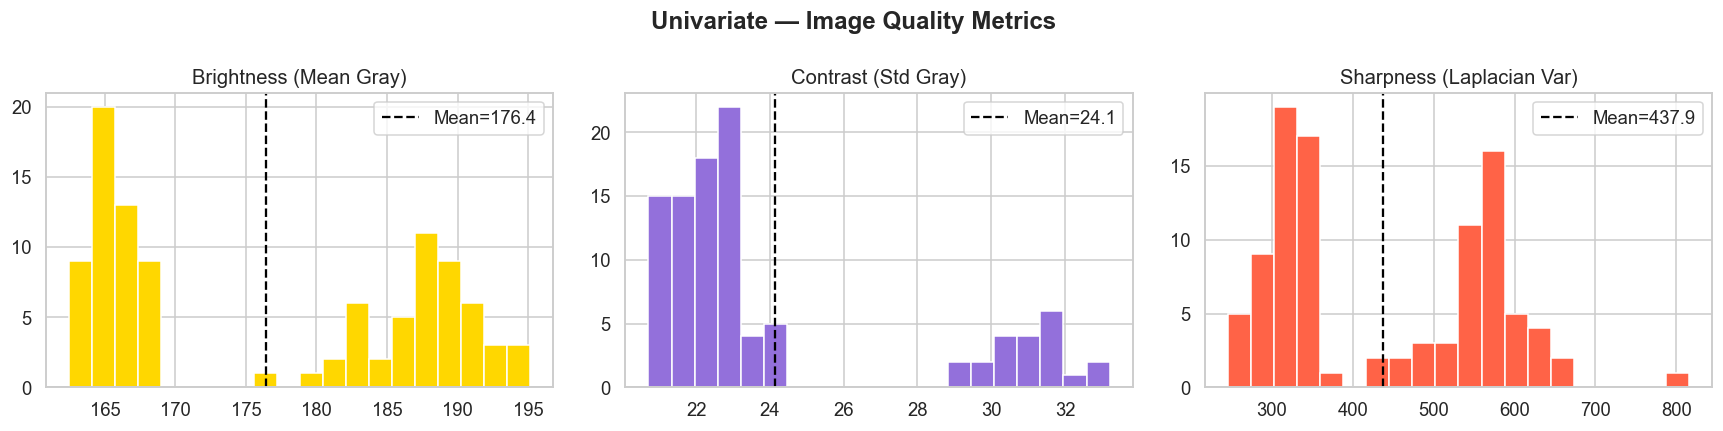

In [10]:
# ── 4.2 Pixel Intensity (Brightness, Contrast, Sharpness) ─────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col, color, title in zip(
    axes,
    ['brightness', 'contrast', 'sharpness'],
    ['gold', 'mediumpurple', 'tomato'],
    ['Brightness (Mean Gray)', 'Contrast (Std Gray)', 'Sharpness (Laplacian Var)']
):
    ax.hist(df_clean[col], bins=20, color=color, edgecolor='white')
    mean_val = df_clean[col].mean()
    ax.axvline(mean_val, color='black', linestyle='--', label=f'Mean={mean_val:.1f}')
    ax.set_title(title); ax.legend()

plt.suptitle('Univariate — Image Quality Metrics', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(CFG['results_dir'], 'univariate_quality.png'), bbox_inches='tight')
plt.show()

Computing aggregate channel histograms over all images...


Channel histograms: 100%|██████████| 100/100 [00:02<00:00, 35.69it/s]


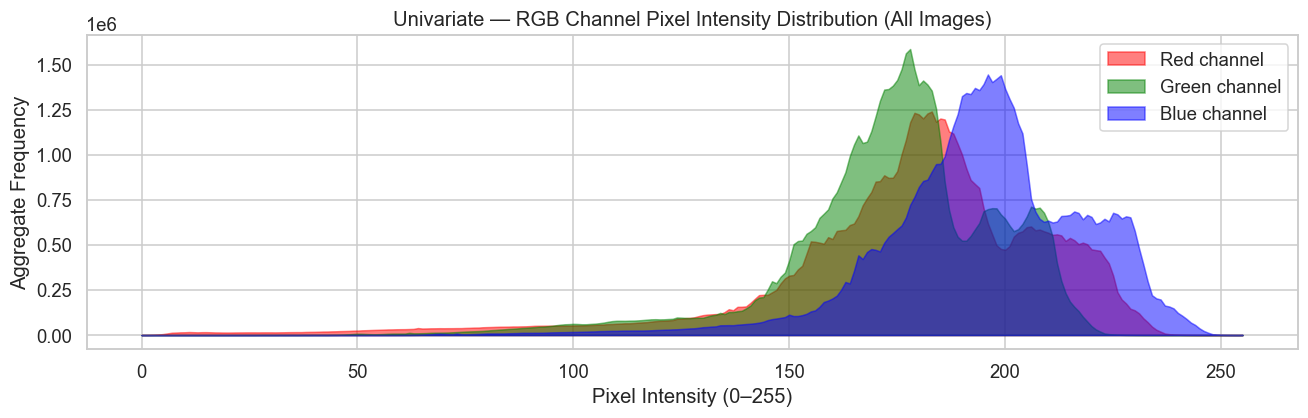

In [11]:
# ── 4.3 Per-channel pixel intensity histograms (aggregate over all images) ────
print('Computing aggregate channel histograms over all images...')
hist_r = np.zeros(256); hist_g = np.zeros(256); hist_b = np.zeros(256)

for fp in tqdm(df_clean['filepath'].tolist(), desc='Channel histograms'):
    img = cv2.imread(fp)
    if img is None: continue
    b, g, r = cv2.split(img)
    hist_r += np.bincount(r.flatten(), minlength=256)
    hist_g += np.bincount(g.flatten(), minlength=256)
    hist_b += np.bincount(b.flatten(), minlength=256)

fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(256)
ax.fill_between(x, hist_r, alpha=0.5, color='red',   label='Red channel')
ax.fill_between(x, hist_g, alpha=0.5, color='green', label='Green channel')
ax.fill_between(x, hist_b, alpha=0.5, color='blue',  label='Blue channel')
ax.set_xlabel('Pixel Intensity (0–255)')
ax.set_ylabel('Aggregate Frequency')
ax.set_title('Univariate — RGB Channel Pixel Intensity Distribution (All Images)')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(CFG['results_dir'], 'univariate_channels.png'), bbox_inches='tight')
plt.show()

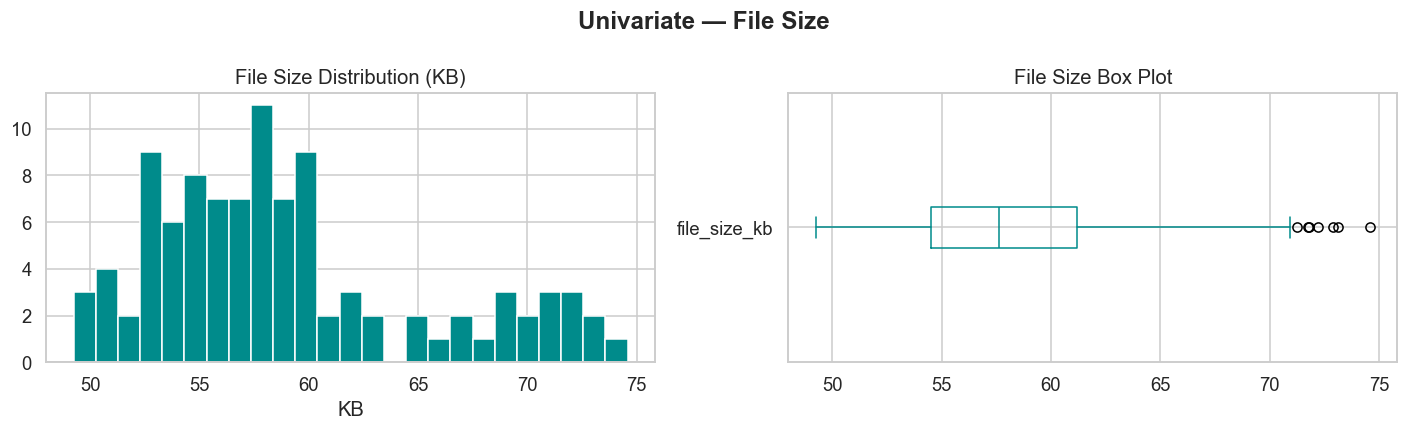

count    100.00
mean      58.98
std        6.26
min       49.25
25%       54.53
50%       57.61
75%       61.20
max       74.58
Name: file_size_kb, dtype: float64


In [12]:
# ── 4.4 File Size Distribution ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df_clean['file_size_kb'], bins=25, color='darkcyan', edgecolor='white')
axes[0].set_title('File Size Distribution (KB)'); axes[0].set_xlabel('KB')

df_clean['file_size_kb'].plot.box(ax=axes[1], vert=False, color='darkcyan')
axes[1].set_title('File Size Box Plot')

plt.suptitle('Univariate — File Size', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(CFG['results_dir'], 'univariate_filesize.png'), bbox_inches='tight')
plt.show()

print(df_clean['file_size_kb'].describe().round(2))

## Section 5 — Bivariate Analysis

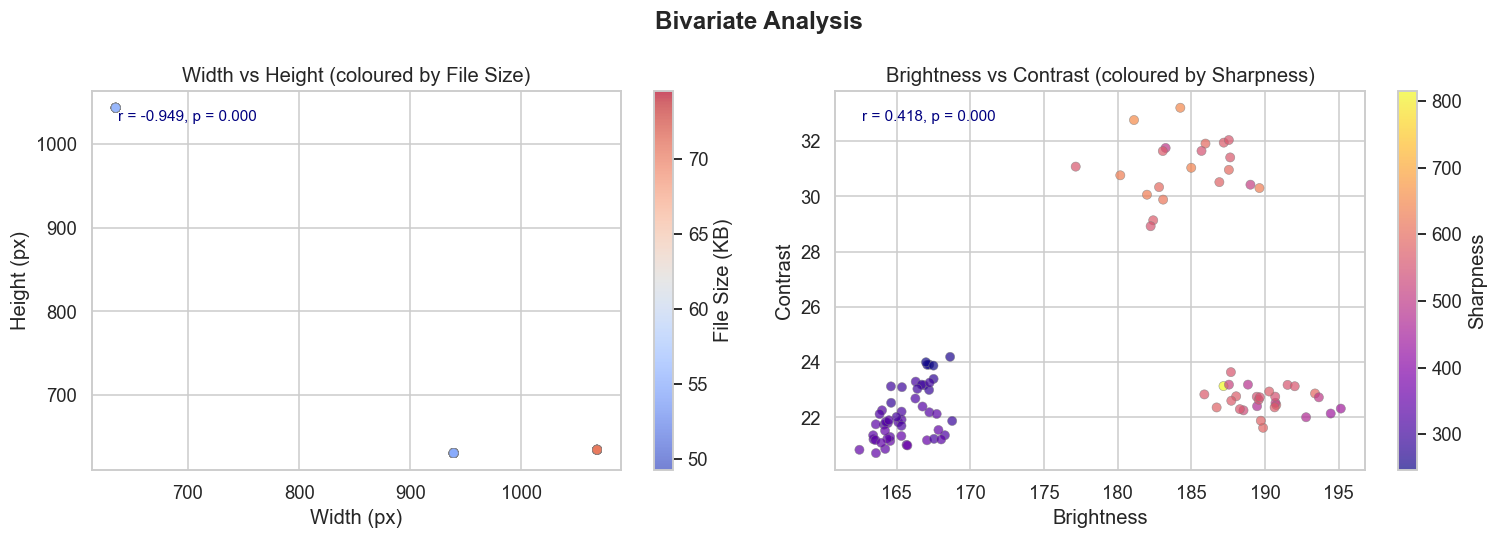

In [13]:
# ── 5.1 Width vs Height scatter ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sc = axes[0].scatter(df_clean['width'], df_clean['height'],
                     c=df_clean['file_size_kb'], cmap='coolwarm', alpha=0.7, edgecolors='grey', linewidth=0.4)
plt.colorbar(sc, ax=axes[0], label='File Size (KB)')
axes[0].set_xlabel('Width (px)'); axes[0].set_ylabel('Height (px)')
axes[0].set_title('Width vs Height (coloured by File Size)')

# Pearson r
r, p = stats.pearsonr(df_clean['width'], df_clean['height'])
axes[0].annotate(f'r = {r:.3f}, p = {p:.3f}', xy=(0.05, 0.92), xycoords='axes fraction',
                 fontsize=10, color='navy')

# ── 5.2 Brightness vs Contrast ─────────────────────────────────────────────────
sc2 = axes[1].scatter(df_clean['brightness'], df_clean['contrast'],
                      c=df_clean['sharpness'], cmap='plasma', alpha=0.7, edgecolors='grey', linewidth=0.4)
plt.colorbar(sc2, ax=axes[1], label='Sharpness')
axes[1].set_xlabel('Brightness'); axes[1].set_ylabel('Contrast')
axes[1].set_title('Brightness vs Contrast (coloured by Sharpness)')
r2, p2 = stats.pearsonr(df_clean['brightness'], df_clean['contrast'])
axes[1].annotate(f'r = {r2:.3f}, p = {p2:.3f}', xy=(0.05, 0.92), xycoords='axes fraction',
                 fontsize=10, color='navy')

plt.suptitle('Bivariate Analysis', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(CFG['results_dir'], 'bivariate_scatter.png'), bbox_inches='tight')
plt.show()

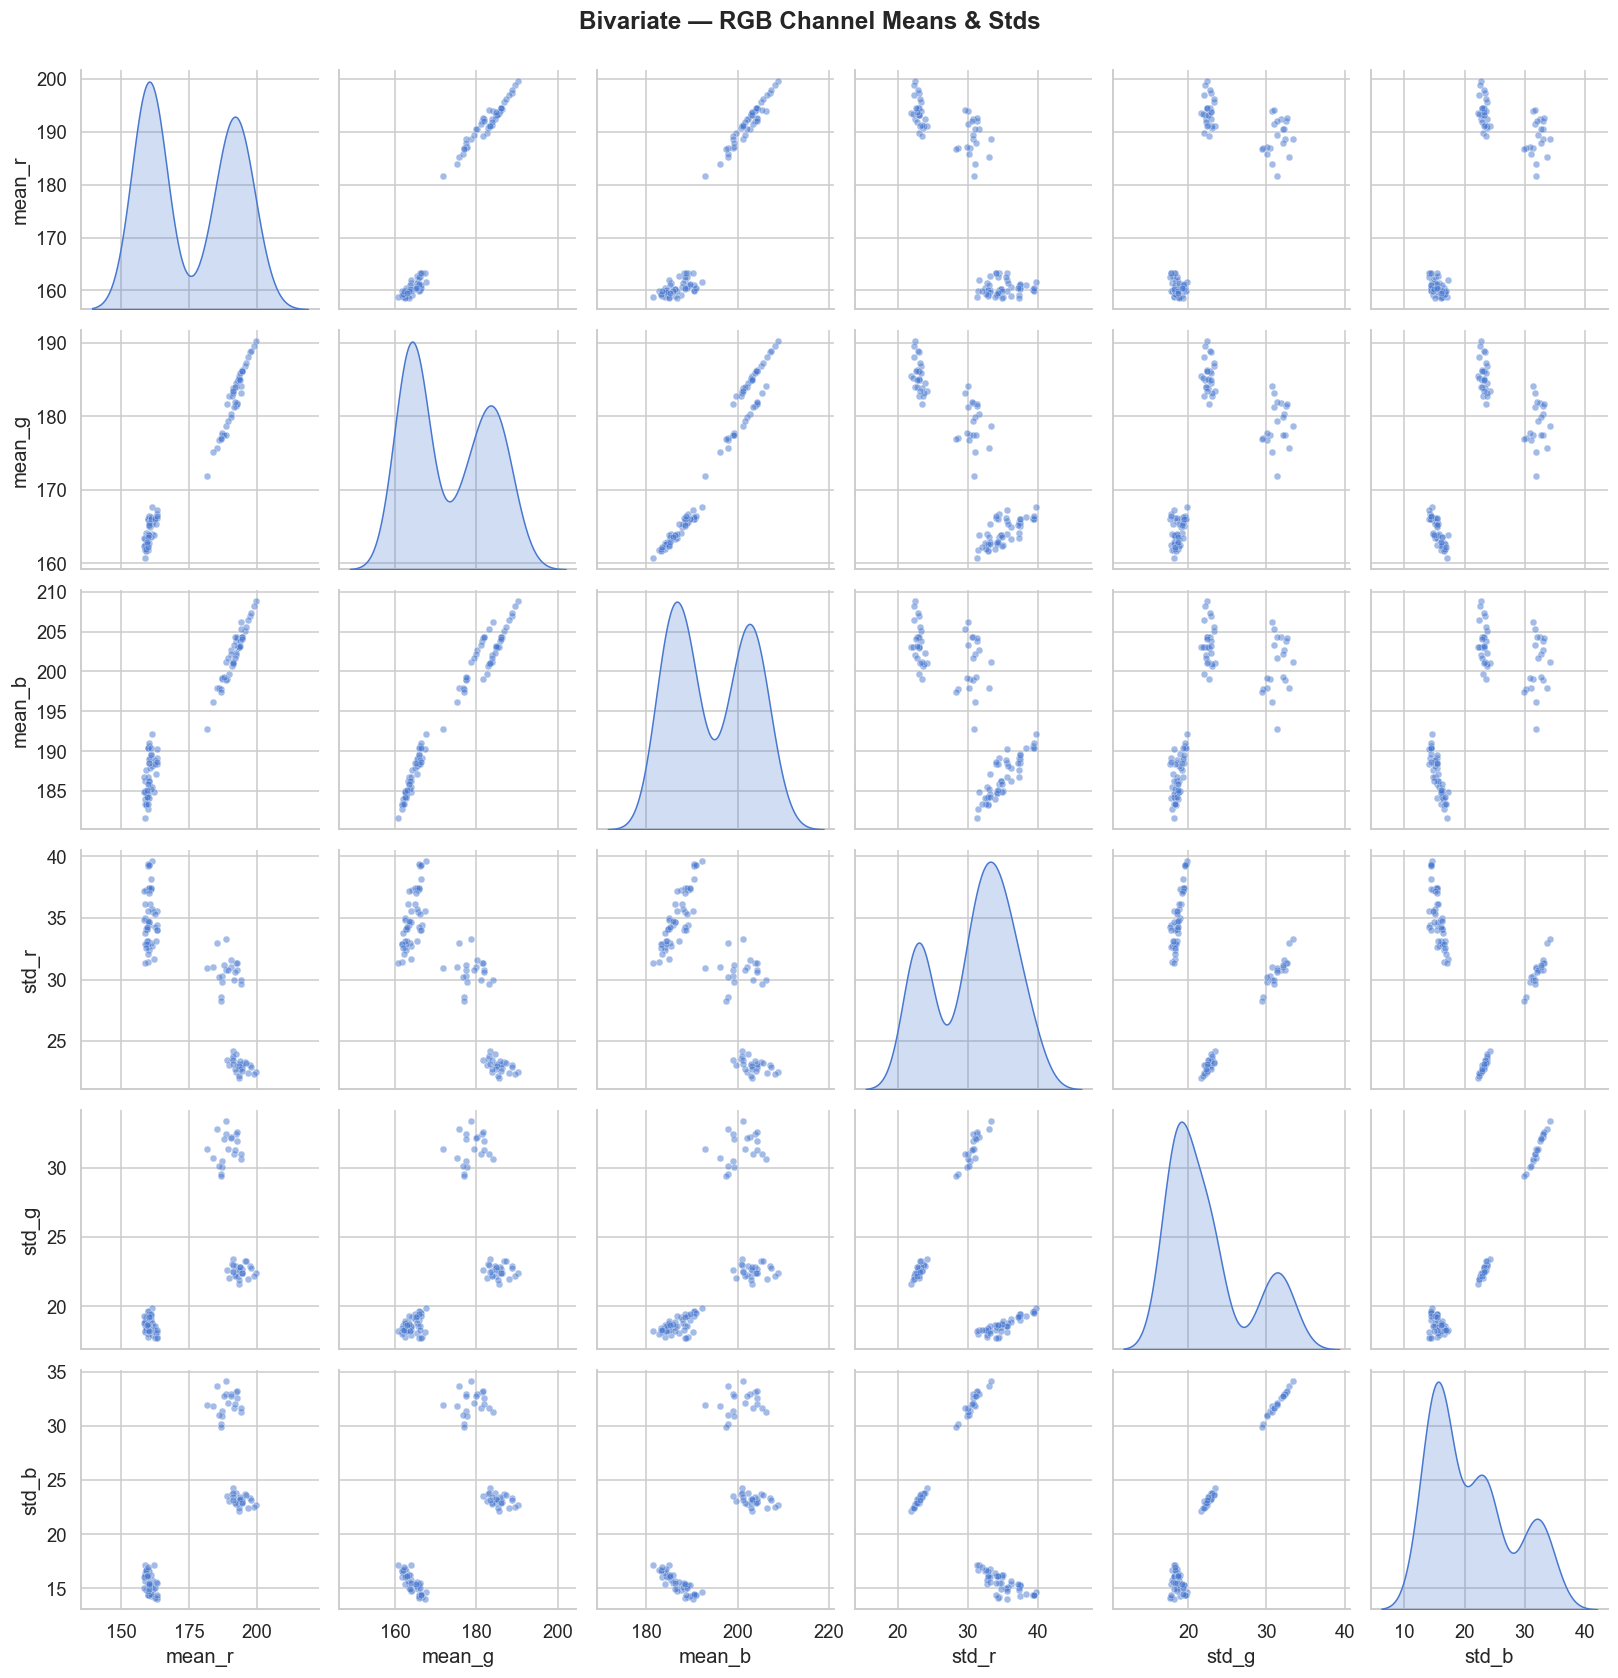

In [14]:
# ── 5.3 RGB channel mean pairplot ─────────────────────────────────────────────
channel_df = df_clean[['mean_r','mean_g','mean_b','std_r','std_g','std_b']]
g = sns.pairplot(channel_df, diag_kind='kde', plot_kws={'alpha':0.5, 's':20})
g.figure.suptitle('Bivariate — RGB Channel Means & Stds', y=1.02, fontweight='bold')
g.figure.savefig(os.path.join(CFG['results_dir'], 'bivariate_channels.png'), bbox_inches='tight')
plt.show()

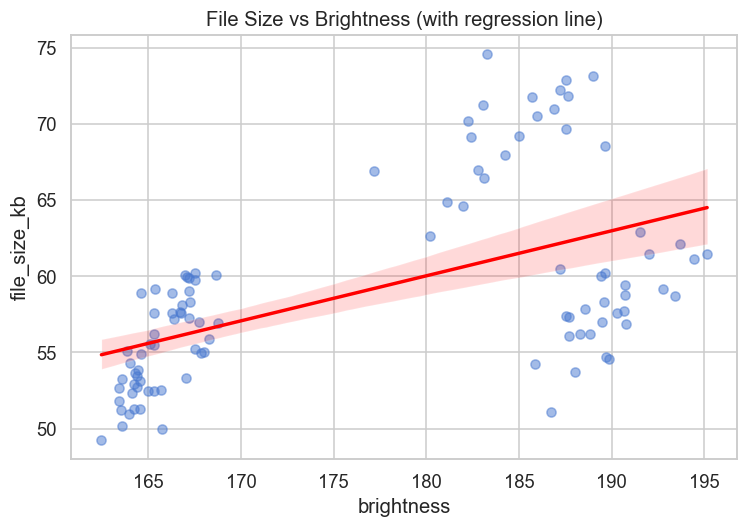

In [15]:
# ── 5.4 Joint Distribution: File Size vs Brightness ───────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(data=df_clean, x='brightness', y='file_size_kb', ax=ax,
            scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
ax.set_title('File Size vs Brightness (with regression line)')
plt.tight_layout()
plt.savefig(os.path.join(CFG['results_dir'], 'bivariate_regplot.png'), bbox_inches='tight')
plt.show()

## Section 6 — Multivariate Analysis

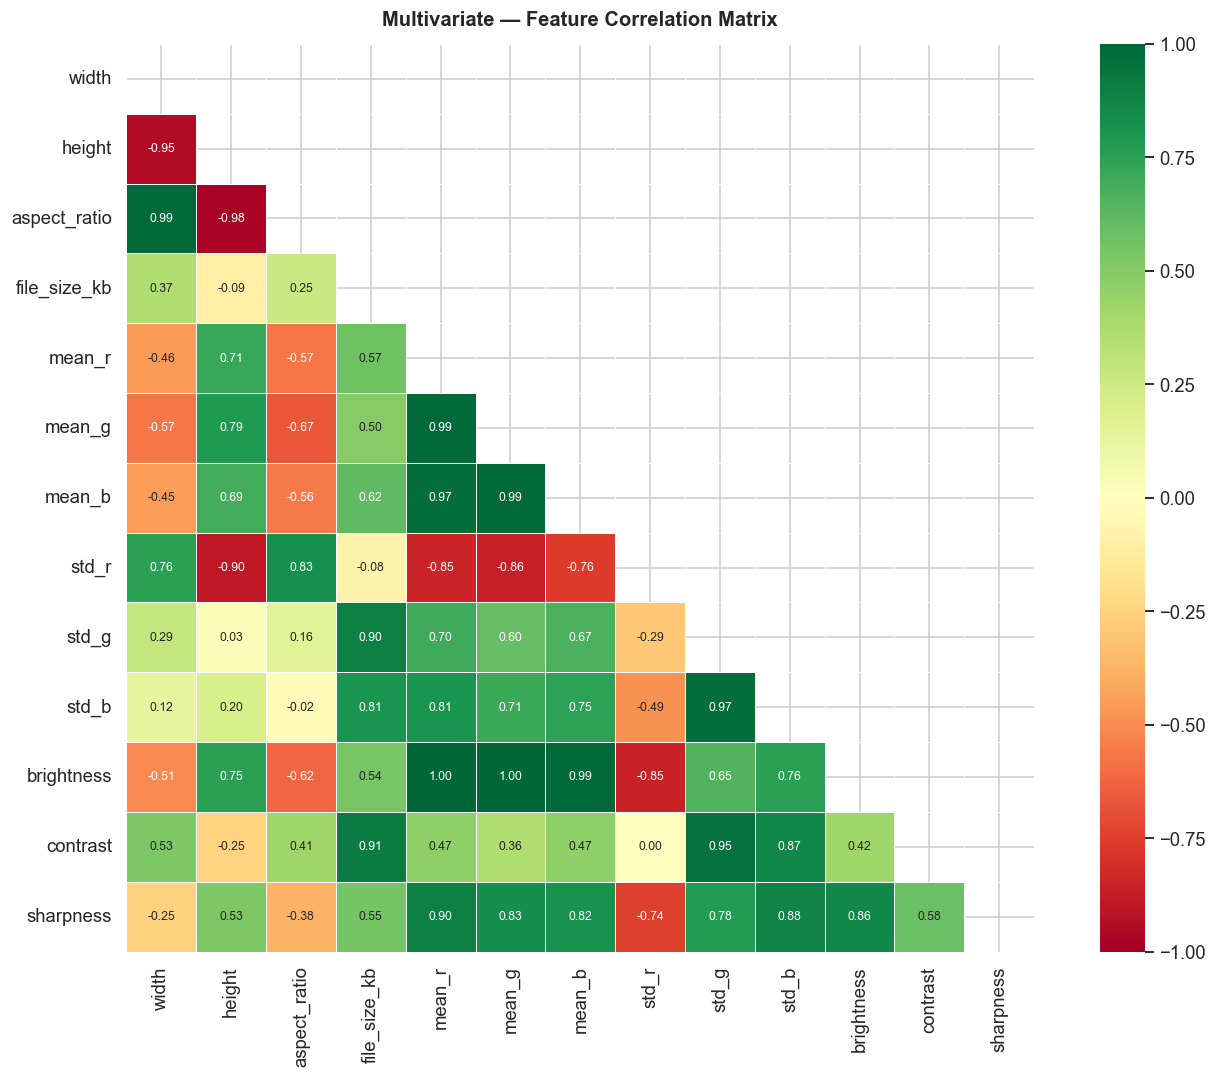


Highly correlated pairs (|r| >= 0.85):
  height <-> width: r = -0.949
  height <-> std_r: r = -0.898
  aspect_ratio <-> width: r = 0.991
  aspect_ratio <-> height: r = -0.983
  file_size_kb <-> std_g: r = 0.895
  mean_r <-> std_r: r = -0.851
  mean_r <-> sharpness: r = 0.897
  mean_g <-> mean_r: r = 0.985
  mean_g <-> std_r: r = -0.860
  mean_b <-> mean_r: r = 0.973
  mean_b <-> mean_g: r = 0.985
  std_b <-> std_g: r = 0.974
  brightness <-> mean_r: r = 0.995
  brightness <-> mean_g: r = 0.997
  brightness <-> mean_b: r = 0.986
  brightness <-> std_r: r = -0.852
  brightness <-> sharpness: r = 0.863
  contrast <-> file_size_kb: r = 0.911
  contrast <-> std_g: r = 0.954
  contrast <-> std_b: r = 0.866
  sharpness <-> std_b: r = 0.876


In [16]:
# ── 6.1 Correlation Matrix ────────────────────────────────────────────────────
feat_cols = ['width','height','aspect_ratio','file_size_kb',
             'mean_r','mean_g','mean_b','std_r','std_g','std_b',
             'brightness','contrast','sharpness']

corr_matrix = df_clean[feat_cols].corr()

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax,
            annot_kws={'size': 8})
ax.set_title('Multivariate — Feature Correlation Matrix', fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig(os.path.join(CFG['results_dir'], 'multivariate_correlation.png'), bbox_inches='tight')
plt.show()

# Highly correlated pairs
threshold = 0.85
high_corr = [(i, j, corr_matrix.loc[i,j])
             for i in feat_cols for j in feat_cols
             if i < j and abs(corr_matrix.loc[i,j]) >= threshold]
if high_corr:
    print(f'\nHighly correlated pairs (|r| >= {threshold}):')
    for a, b, r in high_corr:
        print(f'  {a} <-> {b}: r = {r:.3f}')
else:
    print('No feature pairs with |r| >= 0.85 found.')

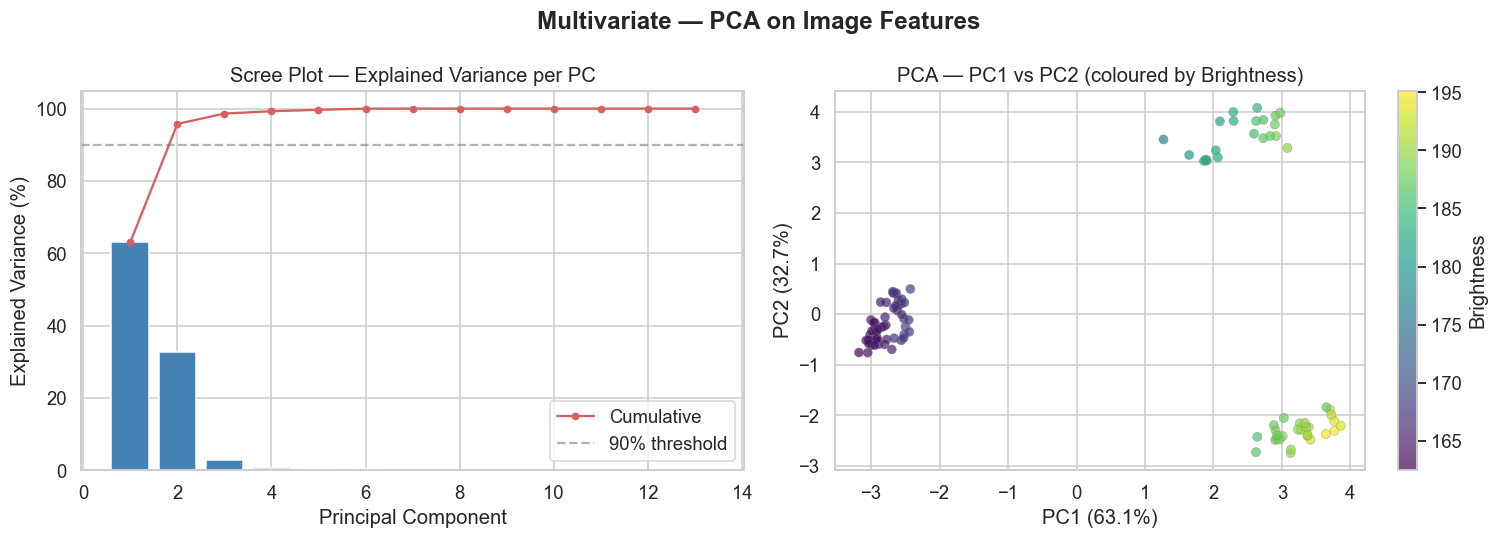

PCs needed to explain 90% variance: 2

Top feature loadings on PC1, PC2, PC3:
                PC1    PC2    PC3
mean_r        0.348 -0.002 -0.016
brightness    0.347 -0.031 -0.133
mean_g        0.343 -0.061 -0.192
mean_b        0.339  0.003 -0.357
sharpness     0.318  0.082  0.530
std_r        -0.295  0.218 -0.375
std_b         0.283  0.265  0.300
height        0.250 -0.336 -0.048
std_g         0.247  0.339  0.113
aspect_ratio -0.201  0.393  0.086
file_size_kb  0.199  0.360 -0.521
contrast      0.168  0.421 -0.013
width        -0.161  0.427  0.113


In [17]:
# ── 6.2 PCA on Image Feature Vector ──────────────────────────────────────────
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = df_clean[feat_cols].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=min(len(feat_cols), len(df_clean)))
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
ev = pca.explained_variance_ratio_ * 100
axes[0].bar(range(1, len(ev)+1), ev, color='steelblue', edgecolor='white')
axes[0].plot(range(1, len(ev)+1), np.cumsum(ev), 'r-o', markersize=4, label='Cumulative')
axes[0].axhline(90, color='gray', linestyle='--', alpha=0.6, label='90% threshold')
axes[0].set_xlabel('Principal Component'); axes[0].set_ylabel('Explained Variance (%)')
axes[0].set_title('Scree Plot — Explained Variance per PC')
axes[0].legend()

# PC1 vs PC2 scatter
sc = axes[1].scatter(X_pca[:, 0], X_pca[:, 1],
                     c=df_clean['brightness'], cmap='viridis', alpha=0.7, edgecolors='grey', linewidth=0.3)
plt.colorbar(sc, ax=axes[1], label='Brightness')
axes[1].set_xlabel(f'PC1 ({ev[0]:.1f}%)')
axes[1].set_ylabel(f'PC2 ({ev[1]:.1f}%)')
axes[1].set_title('PCA — PC1 vs PC2 (coloured by Brightness)')

plt.suptitle('Multivariate — PCA on Image Features', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(CFG['results_dir'], 'multivariate_pca.png'), bbox_inches='tight')
plt.show()

n_for_90 = np.argmax(np.cumsum(ev) >= 90) + 1
print(f'PCs needed to explain 90% variance: {n_for_90}')

# Loadings table
loadings = pd.DataFrame(pca.components_[:3].T, index=feat_cols,
                        columns=['PC1','PC2','PC3']).round(3)
print('\nTop feature loadings on PC1, PC2, PC3:')
print(loadings.sort_values('PC1', key=abs, ascending=False))

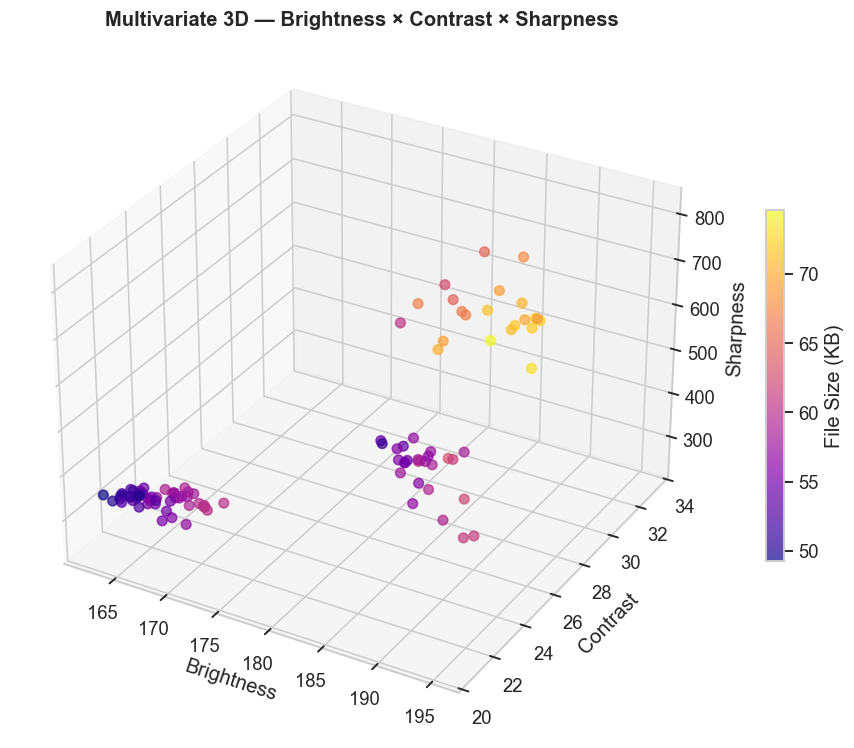

In [18]:
# ── 6.3 3D Scatter — Brightness, Contrast, Sharpness ──────────────────────────
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(df_clean['brightness'], df_clean['contrast'], df_clean['sharpness'],
                c=df_clean['file_size_kb'], cmap='plasma', s=40, alpha=0.7)
fig.colorbar(sc, ax=ax, label='File Size (KB)', shrink=0.5)
ax.set_xlabel('Brightness'); ax.set_ylabel('Contrast'); ax.set_zlabel('Sharpness')
ax.set_title('Multivariate 3D — Brightness × Contrast × Sharpness', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(CFG['results_dir'], 'multivariate_3d.png'), bbox_inches='tight')
plt.show()

## Section 7 — Outlier Detection & Handling

In [19]:
# ── 7.1 IQR Method ────────────────────────────────────────────────────────────
outlier_cols = ['width', 'height', 'file_size_kb', 'brightness', 'contrast', 'sharpness']
iqr_outlier_mask = pd.Series(False, index=df_clean.index)

iqr_report = []
for col in outlier_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    mask = (df_clean[col] < lower) | (df_clean[col] > upper)
    iqr_outlier_mask |= mask
    iqr_report.append({'Feature': col, 'Q1': round(Q1,2), 'Q3': round(Q3,2),
                       'IQR': round(IQR,2), 'Lower': round(lower,2),
                       'Upper': round(upper,2), 'Outlier Count': mask.sum()})

iqr_report_df = pd.DataFrame(iqr_report)
print('=== IQR Outlier Report ===')
print(iqr_report_df.to_string(index=False))
print(f'\nTotal images flagged as outlier by IQR: {iqr_outlier_mask.sum()}')

=== IQR Outlier Report ===
     Feature     Q1      Q3    IQR  Lower   Upper  Outlier Count
       width 635.00  939.00 304.00 179.00 1395.00              0
      height 631.00 1043.00 412.00  13.00 1661.00              0
file_size_kb  54.53   61.20   6.66  44.54   71.19              7
  brightness 165.32  187.70  22.37 131.76  221.26              0
    contrast  21.83   23.88   2.05  18.76   26.95             21
   sharpness 324.11  563.89 239.77 -35.55  923.55              0

Total images flagged as outlier by IQR: 21


In [20]:
# ── 7.2 Z-Score Method ────────────────────────────────────────────────────────
z_scores = np.abs(stats.zscore(df_clean[outlier_cols].fillna(0)))
z_threshold = 3.0
z_outlier_mask = (z_scores > z_threshold).any(axis=1)
z_outlier_mask = pd.Series(z_outlier_mask, index=df_clean.index)

print(f'Z-Score (|z|>{z_threshold}) outliers: {z_outlier_mask.sum()}')

# ── 7.3 Isolation Forest (multivariate) ────────────────────────────────────────
iso_forest = IsolationForest(contamination=0.05, random_state=CFG['random_seed'])
iso_labels = iso_forest.fit_predict(df_clean[outlier_cols].fillna(0))
iso_outlier_mask = pd.Series(iso_labels == -1, index=df_clean.index)
print(f'Isolation Forest outliers: {iso_outlier_mask.sum()}')

# Combined flag
df_clean['is_outlier_iqr'] = iqr_outlier_mask.values
df_clean['is_outlier_zscore'] = z_outlier_mask.values
df_clean['is_outlier_isoforest'] = iso_outlier_mask.values
df_clean['outlier_votes'] = (df_clean['is_outlier_iqr'].astype(int) +
                              df_clean['is_outlier_zscore'].astype(int) +
                              df_clean['is_outlier_isoforest'].astype(int))
df_clean['confirmed_outlier'] = df_clean['outlier_votes'] >= 2  # flagged by ≥2 methods

Z-Score (|z|>3.0) outliers: 0
Isolation Forest outliers: 5


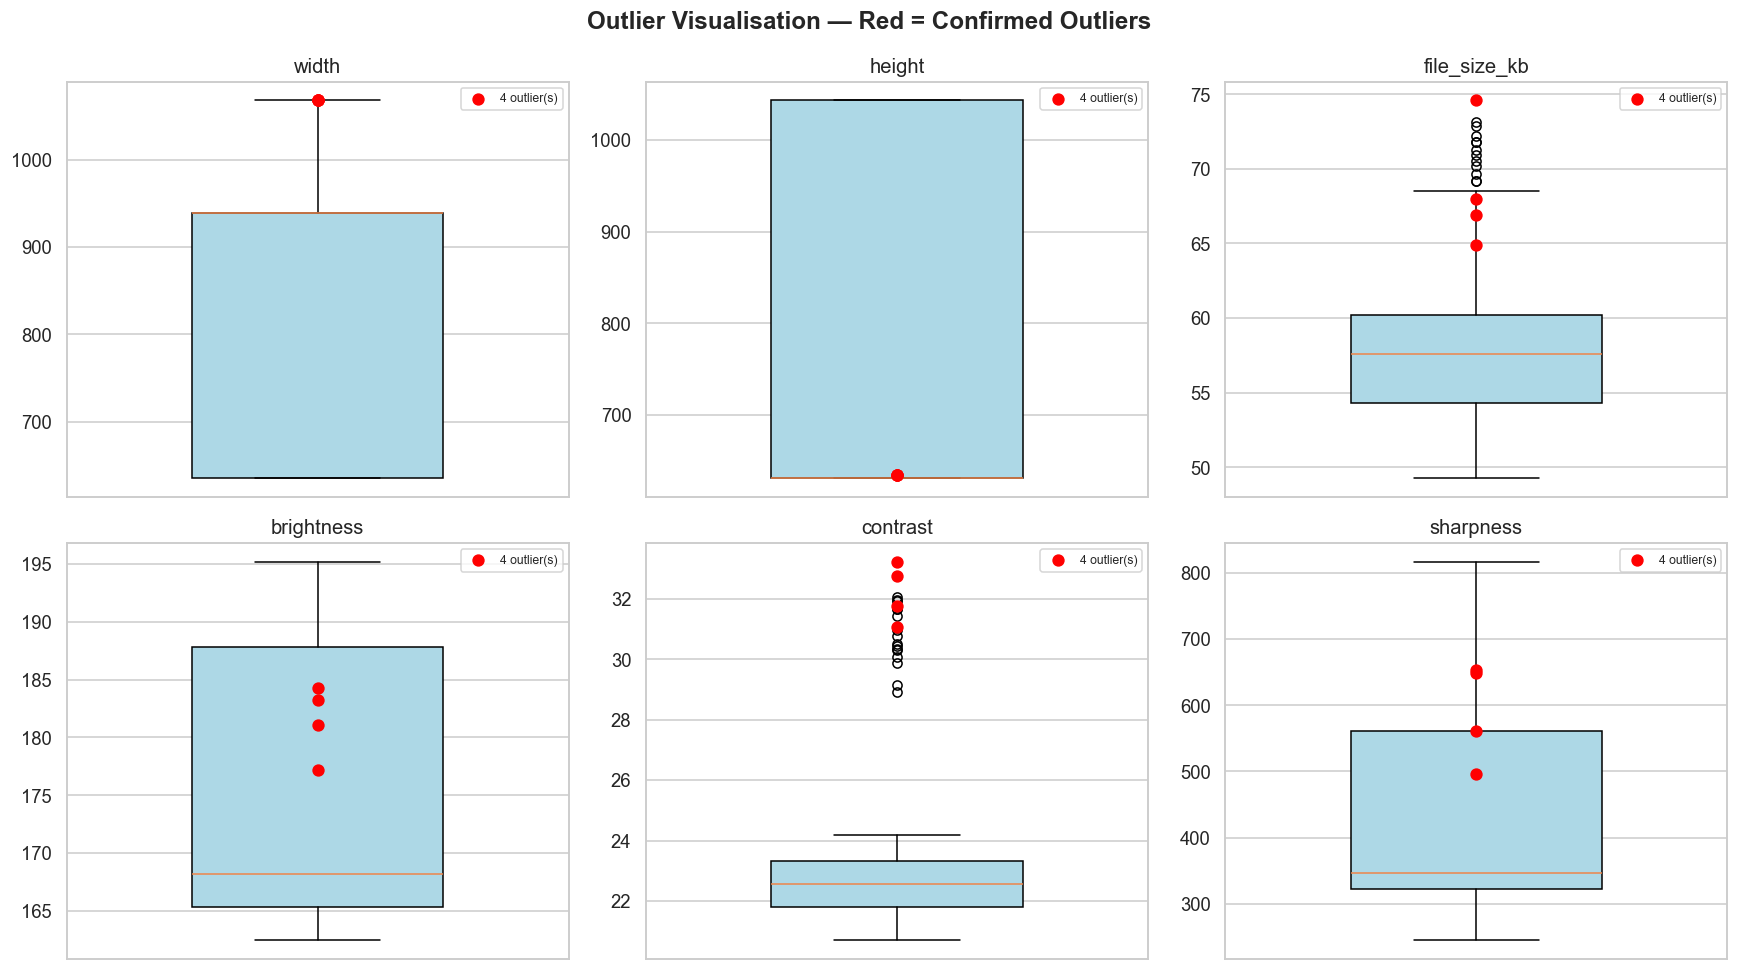


Confirmed outliers (4 images):
            filename  width  height  brightness  contrast  sharpness  file_size_kb
thyrocare_0_2737.jpg   1068     635    181.1082   32.7655   653.5478         64.87
thyrocare_0_4979.jpg   1068     635    184.2530   33.2092   649.0234         67.98
thyrocare_0_5816.jpg   1068     635    183.2562   31.7546   496.4177         74.58
 thyrocare_0_657.jpg   1068     635    177.1490   31.0782   560.3492         66.88


In [21]:
# ── 7.4 Visualise Outliers ────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, outlier_cols):
    normal   = df_clean[~df_clean['confirmed_outlier']][col]
    outliers = df_clean[ df_clean['confirmed_outlier']][col]
    ax.boxplot([normal.dropna()], positions=[1], widths=0.5,
               patch_artist=True, boxprops=dict(facecolor='lightblue'))
    ax.scatter([1]*len(outliers), outliers, color='red', zorder=5,
               s=50, label=f'{len(outliers)} outlier(s)')
    ax.set_title(col); ax.set_xticks([]); ax.legend(fontsize=8)

plt.suptitle('Outlier Visualisation — Red = Confirmed Outliers', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(CFG['results_dir'], 'outlier_boxplots.png'), bbox_inches='tight')
plt.show()

print(f'\nConfirmed outliers ({df_clean["confirmed_outlier"].sum()} images):')
print(df_clean[df_clean['confirmed_outlier']][['filename','width','height',
      'brightness','contrast','sharpness','file_size_kb']].to_string(index=False))

In [22]:
# ── 7.5 Outlier Handling Decision ────────────────────────────────────────────
# For training: retain mildly different images (they add diversity)
# Remove only images that are clearly damaged (very dark, tiny, or corrupt)
severe_outlier_mask = (
    (df_clean['brightness'] < 30) |            # near-black image
    (df_clean['file_size_kb'] < 5)  |          # suspiciously small file
    (df_clean['sharpness'] < 5)     |          # completely blurry
    (~df_clean['readable'])
)

df_final = df_clean[~severe_outlier_mask].copy().reset_index(drop=True)
removed  = df_clean[severe_outlier_mask][['filename','brightness','file_size_kb','sharpness']]

print(f'Images before outlier removal : {len(df_clean)}')
print(f'Images after outlier removal  : {len(df_final)}')
if not removed.empty:
    print('\nRemoved images:')
    print(removed.to_string(index=False))

df_final.to_csv(os.path.join(CFG['output_dir'], 'image_metadata_clean.csv'), index=False)
print(f'\nClean metadata saved → {CFG["output_dir"]}/image_metadata_clean.csv')

Images before outlier removal : 100
Images after outlier removal  : 100

Clean metadata saved → C:\Users\ecsbb\OneDrive\Desktop\Sarita_AIML_Sessions\NextHikesInternship\Project10\output/image_metadata_clean.csv


## Section 8 — YOLO Dataset Preparation & Annotation

In [23]:
# ── 8.1 Auto-generate YOLO annotations ───────────────────────────────────────
# Strategy: detect the main content/table region in each lab report using
# Otsu thresholding + largest contour bounding box as class-0 annotation.
# For production, replace this with LabelImg manual annotations.

def auto_annotate_lab_report(img_path, margin=0.05):
    """Return YOLO annotation string for the primary data-table region."""
    img  = cv2.imread(img_path)
    if img is None:
        return None
    h, w = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Threshold + find table region
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (20, 3))
    dilated = cv2.dilate(thresh, kernel, iterations=3)
    contours, _ = cv2.findContours(dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if not contours:
        # Fallback: annotate centre 80% of image
        return f'0 0.5 0.5 0.9 0.8'

    # Find the largest contour as the main content area
    main = max(contours, key=cv2.contourArea)
    x, y, bw, bh = cv2.boundingRect(main)

    # Clamp with margin
    x  = max(0, x - int(margin * w))
    y  = max(0, y - int(margin * h))
    bw = min(w - x, bw + 2 * int(margin * w))
    bh = min(h - y, bh + 2 * int(margin * h))

    # YOLO format: class cx cy w h  (all normalised 0-1)
    cx = (x + bw / 2) / w
    cy = (y + bh / 2) / h
    nw = bw / w
    nh = bh / h
    return f'0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}'

print('Auto-annotation function defined.')
print('NOTE: For better accuracy, replace auto-annotations with LabelImg manual labels.')
print('LabelImg: https://github.com/HumanSignal/labelImg')

Auto-annotation function defined.
NOTE: For better accuracy, replace auto-annotations with LabelImg manual labels.
LabelImg: https://github.com/HumanSignal/labelImg


In [24]:
# ── 8.2 Resize images to YOLO input size & write annotations ─────────────────
from sklearn.model_selection import train_test_split

np.random.seed(CFG['random_seed'])
img_paths = df_final['filepath'].tolist()

# Split
train_paths, temp_paths = train_test_split(img_paths, test_size=1-CFG['train_split'],
                                            random_state=CFG['random_seed'])
val_paths, test_paths   = train_test_split(temp_paths,
                                            test_size=CFG['test_split'] /
                                                      (CFG['val_split'] + CFG['test_split']),
                                            random_state=CFG['random_seed'])

print(f'Train: {len(train_paths)}  |  Val: {len(val_paths)}  |  Test: {len(test_paths)}')

def process_split(paths, split_name):
    img_out = os.path.join(CFG['yolo_dir'], 'images', split_name)
    lbl_out = os.path.join(CFG['yolo_dir'], 'labels', split_name)
    target_size = (CFG['img_size'], CFG['img_size'])
    ok, skipped = 0, 0
    for fp in tqdm(paths, desc=f'Processing {split_name}'):
        img = cv2.imread(fp)
        if img is None: skipped += 1; continue
        resized = cv2.resize(img, target_size, interpolation=cv2.INTER_LINEAR)
        fname = Path(fp).stem
        cv2.imwrite(os.path.join(img_out, fname + '.jpg'), resized)
        ann = auto_annotate_lab_report(fp)
        if ann:
            with open(os.path.join(lbl_out, fname + '.txt'), 'w') as f:
                f.write(ann)
        ok += 1
    print(f'{split_name}: {ok} OK, {skipped} skipped')

process_split(train_paths, 'train')
process_split(val_paths,   'val')
process_split(test_paths,  'test')

Train: 80  |  Val: 10  |  Test: 10


Processing train: 100%|██████████| 80/80 [00:02<00:00, 33.86it/s]


train: 80 OK, 0 skipped


Processing val: 100%|██████████| 10/10 [00:00<00:00, 31.11it/s]


val: 10 OK, 0 skipped


Processing test: 100%|██████████| 10/10 [00:00<00:00, 26.86it/s]

test: 10 OK, 0 skipped


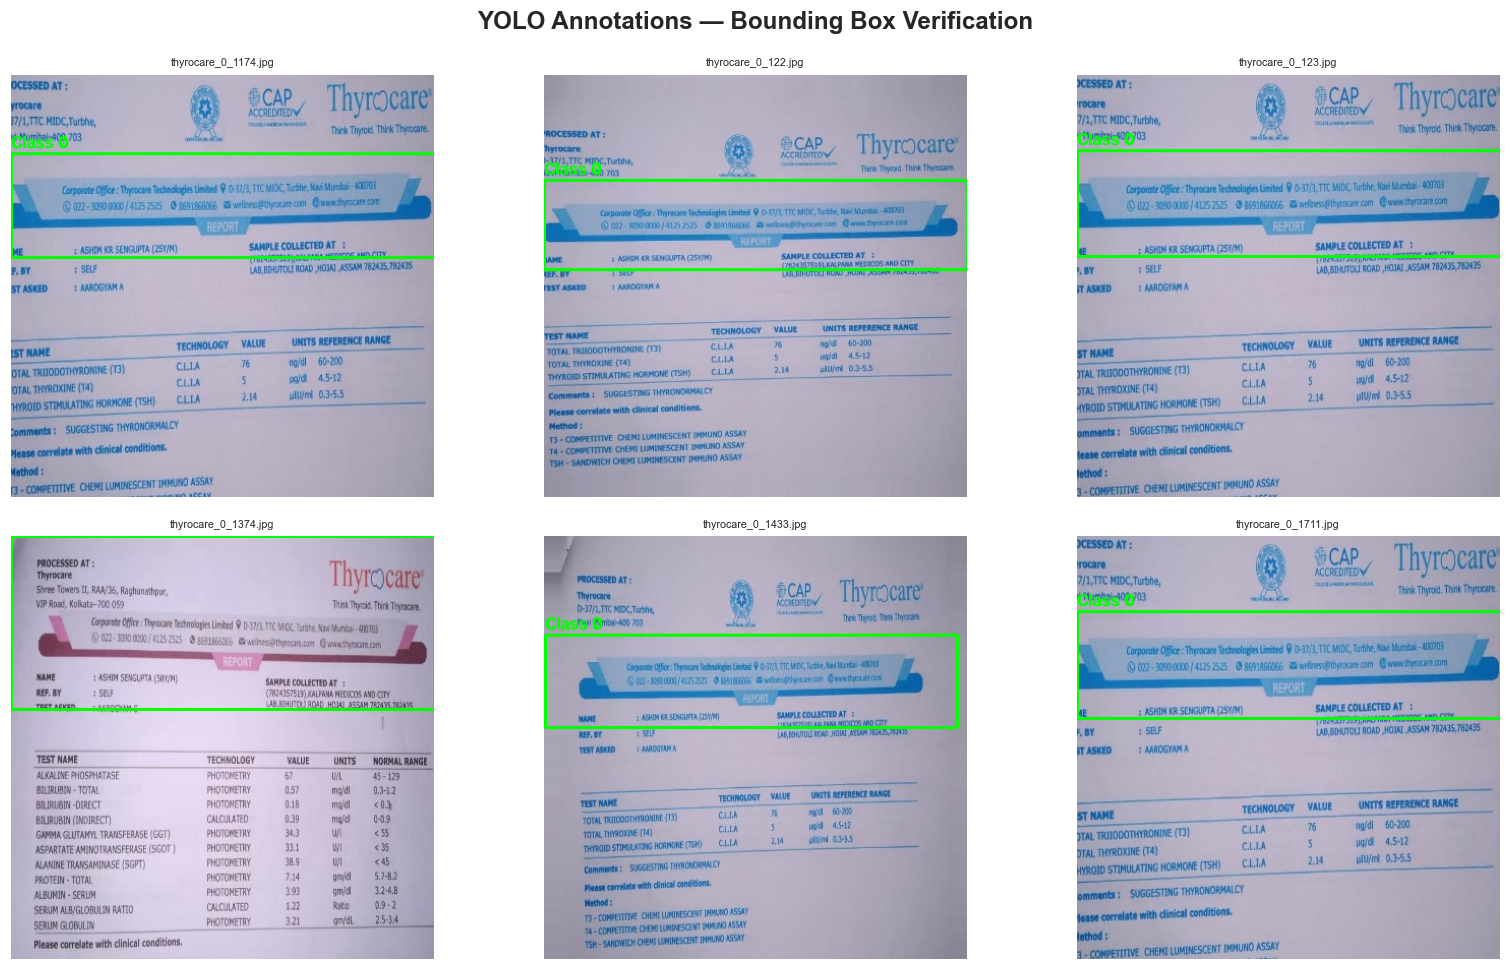

In [25]:
# ── 8.3 Verify annotations on sample images ───────────────────────────────────
def draw_yolo_box(img, ann_str):
    h, w = img.shape[:2]
    cls, cx, cy, bw, bh = map(float, ann_str.strip().split())
    x1 = int((cx - bw/2) * w); y1 = int((cy - bh/2) * h)
    x2 = int((cx + bw/2) * w); y2 = int((cy + bh/2) * h)
    out = img.copy()
    cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(out, f'Class {int(cls)}', (x1, y1-5),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    return out

train_img_dir = os.path.join(CFG['yolo_dir'], 'images', 'train')
train_lbl_dir = os.path.join(CFG['yolo_dir'], 'labels', 'train')
sample_files  = sorted(os.listdir(train_img_dir))[:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, fname in zip(axes.flat, sample_files):
    img = cv2.imread(os.path.join(train_img_dir, fname))
    lbl_path = os.path.join(train_lbl_dir, Path(fname).stem + '.txt')
    if os.path.exists(lbl_path):
        ann = open(lbl_path).read()
        img = draw_yolo_box(img, ann)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(fname, fontsize=7); ax.axis('off')

plt.suptitle('YOLO Annotations — Bounding Box Verification', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(CFG['results_dir'], 'annotation_check.png'), bbox_inches='tight')
plt.show()

In [26]:
# ── 8.4 Write YOLO config files ───────────────────────────────────────────────
# obj.names
names_path = os.path.join(CFG['yolo_dir'], 'obj.names')
with open(names_path, 'w') as f:
    f.write('\n'.join(CFG['class_names']))

# obj.data
data_path = os.path.join(CFG['yolo_dir'], 'obj.data')
with open(data_path, 'w') as f:
    f.write(f'classes = {CFG["num_classes"]}\n')
    f.write(f'train   = {os.path.join(CFG["yolo_dir"], "train.txt")}\n')
    f.write(f'valid   = {os.path.join(CFG["yolo_dir"], "val.txt")}\n')
    f.write(f'names   = {names_path}\n')
    f.write(f'backup  = {CFG["model_dir"]}\n')

# train.txt / val.txt — list of image paths
for split in ['train', 'val', 'test']:
    img_dir  = os.path.join(CFG['yolo_dir'], 'images', split)
    txt_file = os.path.join(CFG['yolo_dir'], f'{split}.txt')
    with open(txt_file, 'w') as f:
        for fname in sorted(os.listdir(img_dir)):
            f.write(os.path.join(img_dir, fname) + '\n')

print(f'Config written:')
print(f'  obj.names : {names_path}')
print(f'  obj.data  : {data_path}')

Config written:
  obj.names : C:\Users\ecsbb\OneDrive\Desktop\Sarita_AIML_Sessions\NextHikesInternship\Project10\yolo_dataset\obj.names
  obj.data  : C:\Users\ecsbb\OneDrive\Desktop\Sarita_AIML_Sessions\NextHikesInternship\Project10\yolo_dataset\obj.data


## Section 9 — YOLOv3 Training

In [27]:
# ── 9.1 Clone & compile darknet (Colab / Linux) ───────────────────────────────
# On Windows, use pre-compiled darknet or ultralytics fallback below
if IN_COLAB:
    !git clone https://github.com/AlexeyAB/darknet /content/darknet
    %cd /content/darknet
    # Enable GPU + OpenCV in Makefile
    !sed -i 's/GPU=0/GPU=1/' Makefile
    !sed -i 's/CUDNN=0/CUDNN=1/' Makefile
    !sed -i 's/OPENCV=0/OPENCV=1/' Makefile
    !make -j4 2>&1 | tail -5
    !./darknet detector --version
    DARKNET_DIR = '/content/darknet'
else:
    # Windows: download pre-compiled darknet or use ultralytics fallback
    DARKNET_DIR = r'C:\darknet'
    print('Windows detected — using ultralytics fallback for YOLOv3.')

print(f'Darknet dir: {DARKNET_DIR}')

Windows detected — using ultralytics fallback for YOLOv3.
Darknet dir: C:\darknet


In [28]:
# ── 9.2 Generate yolov3-custom.cfg ───────────────────────────────────────────
import urllib.request

def create_yolov3_cfg(num_classes, output_path, img_size=416):
    """Generate a minimal yolov3-custom.cfg for the given number of classes."""
    # filters = (num_classes + 5) * 3
    filters = (num_classes + 5) * 3

    # Download base cfg
    base_url = 'https://raw.githubusercontent.com/AlexeyAB/darknet/master/cfg/yolov3.cfg'
    tmp_path  = output_path + '.tmp'
    try:
        urllib.request.urlretrieve(base_url, tmp_path)
        with open(tmp_path, 'r') as f:
            cfg = f.read()
        # Set input resolution
        cfg = cfg.replace('width=608',  f'width={img_size}')
        cfg = cfg.replace('height=608', f'height={img_size}')
        # Patch all [yolo] layers
        import re
        cfg = re.sub(r'(classes=)\d+', f'\\g<1>{num_classes}', cfg)
        # Patch filters in [convolutional] before each [yolo]
        lines = cfg.split('\n')
        new_lines = []
        for i, line in enumerate(lines):
            if line.strip().startswith('filters=') and i+1 < len(lines):
                # Only patch if the section directly precedes a [yolo] layer
                # Look ahead
                look = '\n'.join(lines[i:i+10])
                if '[yolo]' in look:
                    new_lines.append(f'filters={filters}')
                    continue
            new_lines.append(line)
        with open(output_path, 'w') as f:
            f.write('\n'.join(new_lines))
        os.remove(tmp_path)
        print(f'Config written: {output_path}  (classes={num_classes}, filters={filters})')
    except Exception as e:
        print(f'Could not download base cfg: {e}')
        print('Manually place yolov3.cfg in the model folder and adjust classes/filters.')

cfg_path = os.path.join(CFG['model_dir'], 'yolov3-custom.cfg')
create_yolov3_cfg(CFG['num_classes'], cfg_path, CFG['img_size'])

Config written: C:\Users\ecsbb\OneDrive\Desktop\Sarita_AIML_Sessions\NextHikesInternship\Project10\model\yolov3-custom.cfg  (classes=1, filters=18)


In [29]:
# ── 9.3 Download pretrained darknet53 weights ─────────────────────────────────
import os
import urllib.request

weights_url  = 'https://pjreddie.com/media/files/darknet53.conv.74'
pretrain_wts = os.path.join(CFG['model_dir'], 'darknet53.conv.74')

if not os.path.exists(pretrain_wts):
    print('Downloading pretrained darknet53 weights (~160 MB)...')

# Create a request object and fake a real browser user-agent
    req = urllib.request.Request(
        weights_url, 
        headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'}
    )
    
    # Download the data using the faked identity
    with urllib.request.urlopen(req) as response, open(pretrain_wts, 'wb') as out_file:
        data = response.read()
        out_file.write(data)
        
    print('Download complete.')
else:
    print(f'Pretrained weights found: {pretrain_wts}')

Pretrained weights found: C:\Users\ecsbb\OneDrive\Desktop\Sarita_AIML_Sessions\NextHikesInternship\Project10\model\darknet53.conv.74


In [30]:
# ── 9.4 Train YOLOv3 ─────────────────────────────────────────────────────────
if IN_COLAB:
    train_cmd = (
        f'{DARKNET_DIR}/darknet detector train '
        f'{data_path} '
        f'{cfg_path} '
        f'{pretrain_wts} '
        f'-map '
        f'-dont_show'
    )
    print('Starting YOLOv3 training...')
    print(f'Command: {train_cmd}')
    # Uncomment to run (this takes ~1–5 hours on Colab T4 GPU):
    # !{train_cmd}
    print('[INFO] Uncomment the !{train_cmd} line above and run this cell to start training.')
    print('Trained weights will be saved every 1000 iterations to:', CFG['model_dir'])
else:
    print('Windows: run the following in a terminal with darknet compiled:')
    print(f'  darknet.exe detector train {data_path} {cfg_path} {pretrain_wts} -map -dont_show')

BEST_WEIGHTS = os.path.join(CFG['model_dir'], 'yolov3-custom_best.weights')
print(f'\nExpected best weights path: {BEST_WEIGHTS}')

Windows: run the following in a terminal with darknet compiled:
  darknet.exe detector train C:\Users\ecsbb\OneDrive\Desktop\Sarita_AIML_Sessions\NextHikesInternship\Project10\yolo_dataset\obj.data C:\Users\ecsbb\OneDrive\Desktop\Sarita_AIML_Sessions\NextHikesInternship\Project10\model\yolov3-custom.cfg C:\Users\ecsbb\OneDrive\Desktop\Sarita_AIML_Sessions\NextHikesInternship\Project10\model\darknet53.conv.74 -map -dont_show

Expected best weights path: C:\Users\ecsbb\OneDrive\Desktop\Sarita_AIML_Sessions\NextHikesInternship\Project10\model\yolov3-custom_best.weights


In [31]:
# ── 9.5 Training Loss Plot (parse darknet log) ────────────────────────────────
import re

def parse_darknet_log(log_path):
    """Extract iteration and loss from darknet training log."""
    iterations, losses = [], []
    pattern = re.compile(r'^(\d+):.*avg loss ([\d.]+)')
    with open(log_path, 'r', errors='ignore') as f:
        for line in f:
            m = pattern.match(line.strip())
            if m:
                iterations.append(int(m.group(1)))
                losses.append(float(m.group(2)))
    return iterations, losses

log_path = os.path.join(CFG['results_dir'], 'training.log')
if os.path.exists(log_path):
    iters, losses = parse_darknet_log(log_path)
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(iters, losses, color='steelblue', lw=1.2)
    ax.set_xlabel('Iteration'); ax.set_ylabel('Avg Loss')
    ax.set_title('YOLOv3 Training Loss')
    plt.tight_layout()
    plt.savefig(os.path.join(CFG['results_dir'], 'training_loss.png'), bbox_inches='tight')
    plt.show()
else:
    print(f'No training log at {log_path}.')
    print('After training, save darknet output to that path and re-run this cell.')

No training log at C:\Users\ecsbb\OneDrive\Desktop\Sarita_AIML_Sessions\NextHikesInternship\Project10\results\training.log.
After training, save darknet output to that path and re-run this cell.


## Section 10 — Inference + OCR Pipeline

In [32]:
# ── 10.1 YOLOv3 Inference with OpenCV DNN ────────────────────────────────────

class YOLOv3Detector:
    """OpenCV-DNN based YOLOv3 inference wrapper."""

    def __init__(self, weights_path, cfg_path, names_path,
                 conf_thresh=0.5, nms_thresh=0.4, img_size=416):
        self.conf_thresh = conf_thresh
        self.nms_thresh  = nms_thresh
        self.img_size    = img_size
        self.class_names = open(names_path).read().strip().split('\n')

        if not os.path.exists(weights_path):
            raise FileNotFoundError(f'Weights not found: {weights_path}')

        self.net = cv2.dnn.readNetFromDarknet(cfg_path, weights_path)
        self.net.setPreferableBackend(cv2.dnn.DNN_BACKEND_OPENCV)
        self.net.setPreferableTarget(cv2.dnn.DNN_TARGET_CPU)
        self.output_layers = [
            self.net.getLayerNames()[i - 1]
            for i in self.net.getUnconnectedOutLayers().flatten()
        ]

    def detect(self, img):
        """Return list of dicts with keys: class, confidence, box (x,y,w,h)."""
        h, w = img.shape[:2]
        blob = cv2.dnn.blobFromImage(img, 1/255.0,
                                      (self.img_size, self.img_size),
                                      swapRB=True, crop=False)
        self.net.setInput(blob)
        outs = self.net.forward(self.output_layers)

        boxes, confidences, class_ids = [], [], []
        for out in outs:
            for det in out:
                scores = det[5:]
                cid    = int(np.argmax(scores))
                conf   = float(scores[cid])
                if conf < self.conf_thresh:
                    continue
                cx, cy = int(det[0]*w), int(det[1]*h)
                bw, bh = int(det[2]*w), int(det[3]*h)
                x, y   = cx - bw//2, cy - bh//2
                boxes.append([x, y, bw, bh])
                confidences.append(conf)
                class_ids.append(cid)

        indices = cv2.dnn.NMSBoxes(boxes, confidences,
                                    self.conf_thresh, self.nms_thresh)
        results = []
        if len(indices) > 0:
            for i in indices.flatten():
                results.append({
                    'class'     : self.class_names[class_ids[i]],
                    'confidence': round(confidences[i], 4),
                    'box'       : boxes[i]
                })
        return results

print('YOLOv3Detector class defined.')

YOLOv3Detector class defined.


In [33]:
# ── 10.2 Image preprocessing for Tesseract ────────────────────────────────────

def preprocess_crop_for_ocr(crop, scale=3):
    """Resize → grayscale → Gaussian blur → Otsu threshold → bitwise_not."""
    # Scale up for better OCR accuracy
    h, w = crop.shape[:2]
    resized = cv2.resize(crop, (w * scale, h * scale), interpolation=cv2.INTER_CUBIC)
    # Grayscale
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    # Gaussian blur to remove noise
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    # Otsu's binarisation (white text on black)
    _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    # Morphological dilation to connect text components
    kernel   = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
    dilated  = cv2.dilate(thresh, kernel, iterations=1)
    # Flip to black text on white (Tesseract default expectation)
    final = cv2.bitwise_not(dilated)
    return final

def show_preprocessing_steps(crop):
    """Visualise all preprocessing stages side-by-side."""
    h, w = crop.shape[:2]
    resized  = cv2.resize(crop, (w*3, h*3), interpolation=cv2.INTER_CUBIC)
    gray     = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    blurred  = cv2.GaussianBlur(gray, (5, 5), 0)
    _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    final     = cv2.bitwise_not(thresh)

    stages = [
        ('Original Crop',    cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)),
        ('3x Upscaled',      cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)),
        ('Grayscale',        gray),
        ('Gaussian Blur',    blurred),
        ('Otsu Threshold',   thresh),
        ('bitwise_not (OCR)', final),
    ]
    fig, axes = plt.subplots(1, len(stages), figsize=(18, 3))
    for ax, (title, img) in zip(axes, stages):
        cmap = 'gray' if img.ndim == 2 else None
        ax.imshow(img, cmap=cmap); ax.set_title(title, fontsize=8); ax.axis('off')
    plt.suptitle('OCR Preprocessing Pipeline', fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(CFG['results_dir'], 'ocr_preprocessing.png'), bbox_inches='tight')
    plt.show()

print('OCR preprocessing functions defined.')

OCR preprocessing functions defined.


In [34]:
# ── 10.3 Tesseract OCR extraction ─────────────────────────────────────────────

TESS_CONFIG = '--oem 3 --psm 6'

def extract_text_from_crop(preprocessed_img):
    """Run Tesseract on a preprocessed crop and return clean text."""
    pil_img = Image.fromarray(preprocessed_img)
    raw_text = pytesseract.image_to_string(pil_img, config=TESS_CONFIG)
    # Clean up: remove excess whitespace, drop blank lines
    lines = [l.strip() for l in raw_text.split('\n') if l.strip()]
    return ' | '.join(lines)

def run_ocr_pipeline(img_path, detector, save_crops=True):
    """
    Full inference + OCR pipeline for one image.
    Returns list of dicts: {filename, class, confidence, text}.
    """
    img = cv2.imread(img_path)
    if img is None:
        return []
    h, w = img.shape[:2]
    detections = detector.detect(img)
    results = []
    for idx, det in enumerate(detections):
        x, y, bw, bh = det['box']
        # Clamp to image bounds
        x1 = max(0, x);     y1 = max(0, y)
        x2 = min(w, x+bw);  y2 = min(h, y+bh)
        crop = img[y1:y2, x1:x2]
        if crop.size == 0:
            continue
        processed = preprocess_crop_for_ocr(crop)
        text = extract_text_from_crop(processed)

        if save_crops:
            stem  = Path(img_path).stem
            fname = f'{stem}_det{idx}.jpg'
            cv2.imwrite(os.path.join(CFG['crop_dir'], fname), crop)

        results.append({
            'filename'   : Path(img_path).name,
            'class'      : det['class'],
            'confidence' : det['confidence'],
            'box'        : det['box'],
            'ocr_text'   : text
        })
    return results

print('OCR pipeline function defined.')

OCR pipeline function defined.


In [ ]:
# ── 10.4 Run inference on test set ───────────────────────────────────────────
# Load model (only if trained weights exist)
if os.path.exists(BEST_WEIGHTS):
    detector = YOLOv3Detector(
        weights_path = BEST_WEIGHTS,
        cfg_path     = cfg_path,
        names_path   = names_path,
        conf_thresh  = CFG['conf_threshold'],
        nms_thresh   = CFG['nms_threshold'],
        img_size     = CFG['img_size'],
    )
    print('Model loaded successfully.')

    all_ocr_results = []
    test_img_dir    = os.path.join(CFG['yolo_dir'], 'images', 'test')
    test_images     = sorted(os.listdir(test_img_dir))

    for fname in tqdm(test_images, desc='Running inference + OCR'):
        fp = os.path.join(test_img_dir, fname)
        results = run_ocr_pipeline(fp, detector)
        all_ocr_results.extend(results)

    print(f'\nTotal detections: {len(all_ocr_results)}')
else:
    print(f'Trained weights not found at: {BEST_WEIGHTS}')
    print('Train the model first (Section 9), then re-run this cell.')
    print('\nDemonstrating pipeline on raw images (no YOLO — using full-image as crop)...')

    # Demo mode: treat entire image as the crop (no YOLO needed)
    all_ocr_results = []
    demo_paths = df_final['filepath'].tolist()[:5]

    for fp in tqdm(demo_paths, desc='Demo OCR'):
        img = cv2.imread(fp)
        if img is None: continue
        processed = preprocess_crop_for_ocr(img)
        text = extract_text_from_crop(processed)
        all_ocr_results.append({
            'filename'   : Path(fp).name,
            'class'      : 'lab_data_region',
            'confidence' : 1.0,
            'box'        : [0, 0, img.shape[1], img.shape[0]],
            'ocr_text'   : text
        })
    print(f'Demo OCR complete. Results: {len(all_ocr_results)}')

In [36]:
# ── 10.5 Visualise detections on test images ─────────────────────────────────
if os.path.exists(BEST_WEIGHTS) and test_images:
    fig, axes = plt.subplots(1, min(3, len(test_images)), figsize=(15, 6))
    if not hasattr(axes, '__iter__'): axes = [axes]

    for ax, fname in zip(axes, test_images[:3]):
        fp  = os.path.join(test_img_dir, fname)
        img = cv2.imread(fp)
        dets = detector.detect(img)
        for det in dets:
            x, y, bw, bh = det['box']
            cv2.rectangle(img, (x, y), (x+bw, y+bh), (0, 255, 0), 2)
            label = f"{det['class']} {det['confidence']:.2f}"
            cv2.putText(img, label, (x, y-6),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(fname, fontsize=8); ax.axis('off')

    plt.suptitle('YOLOv3 Detections on Test Images', fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(CFG['results_dir'], 'test_detections.png'), bbox_inches='tight')
    plt.show()

## Section 11 — Post-processing & CSV Output

In [41]:
# ── 11.1 Parse OCR text into structured fields ────────────────────────────────
import re

def parse_lab_report_text(raw_text):
    """
    Parse Tesseract output from a Thyrocare lab report into structured fields.
    Extracts: Test Name, Technology, Value, Unit, Reference Range.
    Returns a list of row dicts.
    """
    rows = []
    lines = [l.strip() for l in raw_text.split('|') if l.strip()]

    # Patterns for numeric values and common units
    val_pattern  = re.compile(r'\b(\d+\.?\d*)\b')
    unit_pattern = re.compile(
        r'\b(ng/dl|ng/mL|pg/ml|ug/dl|mIU/L|uIU/ml|g/dl|mg/dl|mmol/L|%)\b',
        re.IGNORECASE
    )
    range_pattern = re.compile(r'(\d+\.?\d*\s*[-–]\s*\d+\.?\d*|>\s*\d+|<\s*\d+)')
    tech_pattern  = re.compile(r'(C\.?L\.?I\.?A\.?|ELISA|PCR|RIA|HPLC)',
                                re.IGNORECASE)

    current_test = None
    for line in lines:
        val_m   = val_pattern.search(line)
        unit_m  = unit_pattern.search(line)
        range_m = range_pattern.search(line)
        tech_m  = tech_pattern.search(line)

        if unit_m or (val_m and range_m):
            rows.append({
                'test_name'      : current_test or line[:40],
                'technology'     : tech_m.group(0)  if tech_m   else '',
                'value'          : val_m.group(0)   if val_m    else '',
                'unit'           : unit_m.group(0)  if unit_m   else '',
                'reference_range': range_m.group(0) if range_m  else '',
                'raw_line'       : line,
            })
        elif not val_m and not unit_m and len(line) > 5:
            current_test = line[:60]

    return rows if rows else [{'test_name': '', 'technology': '',
                                'value': '', 'unit': '',
                                'reference_range': '', 'raw_line': raw_text[:100]}]

# Build results DataFrame
parsed_rows = []
for res in all_ocr_results:
    parsed = parse_lab_report_text(res['ocr_text'])
    for row in parsed:
        row['source_image'] = res['filename']
        row['confidence']   = res['confidence']
        parsed_rows.append(row)

results_df = pd.DataFrame(parsed_rows)
print(f'Parsed rows: {len(results_df)}')
results_df.head(10)

Parsed rows: 0


""


In [ ]:
# ── 11.2 Missing Value Handling on OCR DataFrame ──────────────────────────────
print('=== Missing Values in OCR Results ===')
ocr_missing = results_df.isnull().sum()
ocr_empty   = (results_df == '').sum()
print(pd.DataFrame({'NaN Count': ocr_missing, 'Empty String Count': ocr_empty}))

# Replace empty strings with NaN for uniform handling
results_df.replace('', np.nan, inplace=True)

# Backfill: fill missing technology/unit from the previous row per image
results_df['technology'] = results_df.groupby('source_image')['technology'].ffill().bfill()
results_df['unit']       = results_df.groupby('source_image')['unit'].ffill()

# Drop rows where both test_name and value are missing (unusable)
before = len(results_df)
results_df.dropna(subset=['test_name', 'value'], how='all', inplace=True)
results_df.reset_index(drop=True, inplace=True)
print(f'\nDropped {before - len(results_df)} rows with no test_name AND no value.')

# Fill remaining NaN with placeholder
results_df.fillna('N/A', inplace=True)
print(f'Final rows: {len(results_df)}')
print('\nMissing values after handling:')
print(results_df.isnull().sum())

In [ ]:
# ── 11.3 EDA on Extracted OCR Data ───────────────────────────────────────────
print('=== OCR Results Summary ===')
print(f'Total records     : {len(results_df)}')
print(f'Unique images     : {results_df["source_image"].nunique()}')
print(f'Unique test names : {results_df["test_name"].nunique()}')
print(f'Units found       : {results_df["unit"].unique().tolist()}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tests per image
tpi = results_df.groupby('source_image').size()
axes[0].bar(range(len(tpi)), sorted(tpi.values, reverse=True), color='steelblue')
axes[0].set_xlabel('Image (sorted)'); axes[0].set_ylabel('Detected Test Rows')
axes[0].set_title('Number of Detected Rows per Image')

# Unit distribution
unit_counts = results_df['unit'][results_df['unit'] != 'N/A'].value_counts()
unit_counts.plot.bar(ax=axes[1], color='coral', edgecolor='white')
axes[1].set_title('Unit Distribution in OCR Output')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig(os.path.join(CFG['results_dir'], 'ocr_eda.png'), bbox_inches='tight')
plt.show()

In [ ]:
# ── 11.4 Outlier Detection on Numeric OCR Values ──────────────────────────────
results_df['value_numeric'] = pd.to_numeric(results_df['value'], errors='coerce')
numeric_vals = results_df['value_numeric'].dropna()

if len(numeric_vals) > 3:
    z = np.abs(stats.zscore(numeric_vals))
    ocr_outlier_mask = z > 3
    print(f'Numeric OCR values — outliers (|z|>3): {ocr_outlier_mask.sum()}')

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].hist(numeric_vals, bins=20, color='darkcyan', edgecolor='white')
    axes[0].set_title('Distribution of Numeric Lab Values')
    axes[0].set_xlabel('Value')

    numeric_vals.plot.box(ax=axes[1], vert=False, color='darkcyan')
    axes[1].set_title('Box Plot — Numeric Lab Values')
    plt.tight_layout()
    plt.savefig(os.path.join(CFG['results_dir'], 'ocr_value_distribution.png'), bbox_inches='tight')
    plt.show()
else:
    print('Not enough numeric values extracted for outlier analysis.')

In [ ]:
# ── 11.5 Save final CSV ───────────────────────────────────────────────────────
output_cols = ['source_image', 'test_name', 'technology', 'value', 'unit', 'reference_range', 'confidence']
final_df    = results_df[[c for c in output_cols if c in results_df.columns]].copy()

csv_path = os.path.join(CFG['output_dir'], 'lab_report_ocr_output.csv')
final_df.to_csv(csv_path, index=False)
print(f'CSV saved: {csv_path}')
print(f'Rows: {len(final_df)}  |  Columns: {list(final_df.columns)}')
final_df.head(10)

## Section 12 — Evaluation & Reporting

In [48]:
# ── 12.1 OCR Accuracy Evaluation ─────────────────────────────────────────────
# If you have ground-truth labels, compare here.
# Ground truth format: CSV with columns matching output_cols.

gt_path = os.path.join(CFG['dataset_dir'], 'ground_truth.csv')
if os.path.exists(gt_path):
    gt_df = pd.read_csv(gt_path)
    # Simple exact-match accuracy per field
    merged = pd.merge(final_df, gt_df,
                      on=['source_image', 'test_name'], suffixes=('_pred','_gt'))
    for col in ['value', 'unit', 'reference_range']:
        pred_col = col + '_pred' if col + '_pred' in merged.columns else col
        gt_col   = col + '_gt'   if col + '_gt'   in merged.columns else col
        if pred_col in merged.columns and gt_col in merged.columns:
            acc = (merged[pred_col].astype(str).str.strip() ==
                   merged[gt_col].astype(str).str.strip()).mean() * 100
            print(f'{col:20s} accuracy: {acc:.1f}%')
else:
    print(f'No ground truth file at: {gt_path}')
    print('Place a ground_truth.csv in the dataset directory to enable accuracy evaluation.')

No ground truth file at: C:\Users\ecsbb\OneDrive\Desktop\Sarita_AIML_Sessions\NextHikesInternship\Project10\drive-download-20261013T185652Z-1-001\ground_truth.csv
Place a ground_truth.csv in the dataset directory to enable accuracy evaluation.


Demo image: thyrocare_0_1001.jpg


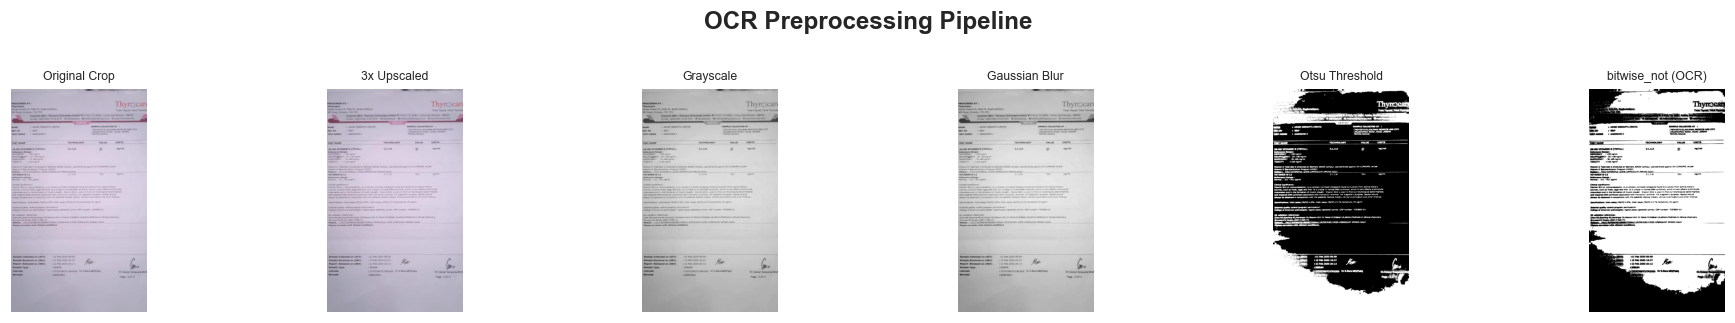

TesseractNotFoundError: C:\Program Files\Tesseract-OCR\tesseract.exe is not installed or it's not in your PATH. See README file for more information.

In [47]:
# ── 12.2 End-to-End Demo — Single Image ──────────────────────────────────────
demo_img_path = df_final['filepath'].iloc[0]
print(f'Demo image: {Path(demo_img_path).name}')

demo_img = cv2.imread(demo_img_path)

if os.path.exists(BEST_WEIGHTS):
    dets  = detector.detect(demo_img)
    x, y, bw, bh = dets[0]['box'] if dets else [0, 0, demo_img.shape[1], demo_img.shape[0]]
    crop  = demo_img[max(0,y):y+bh, max(0,x):x+bw]
else:
    crop = demo_img

proc  = preprocess_crop_for_ocr(crop)
show_preprocessing_steps(crop)

text = extract_text_from_crop(proc)
print('\n=== Tesseract OCR Output ===')
print(text)

parsed = parse_lab_report_text(text)
demo_result = pd.DataFrame(parsed)
print('\n=== Parsed Structured Output ===')
print(demo_result.to_string(index=False))

In [ ]:
# ── 12.3 Summary Report ───────────────────────────────────────────────────────
summary = {
    'Total Images'              : len(all_paths),
    'Readable Images'           : int(df['readable'].sum()),
    'Corrupt Images'            : int((~df['readable']).sum()),
    'Images after Cleanup'      : len(df_clean),
    'Confirmed Outliers'        : int(df_clean['confirmed_outlier'].sum()),
    'Final Training Set'        : len(df_final),
    'Train / Val / Test Split'  : f'{len(train_paths)} / {len(val_paths)} / {len(test_paths)}',
    'YOLO Classes'              : CFG['class_names'],
    'Input Size'                : f'{CFG["img_size"]}×{CFG["img_size"]}',
    'OCR Rows Extracted'        : len(final_df),
    'Output CSV'                : csv_path,
}

print('=' * 55)
print('       PROJECT SUMMARY — Custom OCR Lab Report')
print('=' * 55)
for k, v in summary.items():
    print(f'  {k:<32}: {v}')
print('=' * 55)

# Save summary JSON
summary_path = os.path.join(CFG['output_dir'], 'project_summary.json')
with open(summary_path, 'w') as f:
    json.dump({k: str(v) for k, v in summary.items()}, f, indent=2)
print(f'Summary saved: {summary_path}')

In [ ]:
# ── 12.4 Full Pipeline Automation Function ─────────────────────────────────────
def process_single_image(img_path, detector_model=None):
    """
    End-to-end OCR pipeline for a single lab report image.
    Usage: python Custom_OCR.py --image <yourimage.jpg>
    """
    img = cv2.imread(img_path)
    if img is None:
        raise FileNotFoundError(f'Cannot read image: {img_path}')

    if detector_model is not None:
        dets = detector_model.detect(img)
        crops = []
        for det in dets:
            x, y, bw, bh = det['box']
            crop = img[max(0,y):y+bh, max(0,x):x+bw]
            crops.append(crop)
    else:
        crops = [img]

    all_rows = []
    for crop in crops:
        processed = preprocess_crop_for_ocr(crop)
        text      = extract_text_from_crop(processed)
        rows      = parse_lab_report_text(text)
        all_rows.extend(rows)

    result_df = pd.DataFrame(all_rows)
    result_df['source_image'] = Path(img_path).name
    return result_df

# CLI entry point usage (replicate Custom_OCR.py --image <img>)
import argparse, sys

if __name__ == '__main__' or 'ipykernel' in sys.modules:
    # Jupyter usage — run on demo image
    out = process_single_image(demo_img_path)
    print('=== CLI Demo Output ===')
    print(out.to_string(index=False))
    out_csv = os.path.join(CFG['output_dir'], 'demo_output.csv')
    out.to_csv(out_csv, index=False)
    print(f'\nSaved to: {out_csv}')

## Section 13 — Evaluation & Optimization

> Requirement §5: compare OCR output with ground truth, fine-tune model, optimize preprocessing, improve Tesseract output.

Preprocessing grid search: 27 combinations...

=== Top 10 Preprocessing Configurations ===
 scale  blur_kernel         threshold  mean_conf  word_count
     2            3              otsu        0.0           0
     2            3     adaptive_mean        0.0           0
     2            3 adaptive_gaussian        0.0           0
     2            5              otsu        0.0           0
     2            5     adaptive_mean        0.0           0
     2            5 adaptive_gaussian        0.0           0
     2            7              otsu        0.0           0
     2            7     adaptive_mean        0.0           0
     2            7 adaptive_gaussian        0.0           0
     3            3              otsu        0.0           0

Best: scale=2, blur=3, threshold=otsu  (conf=0.0)


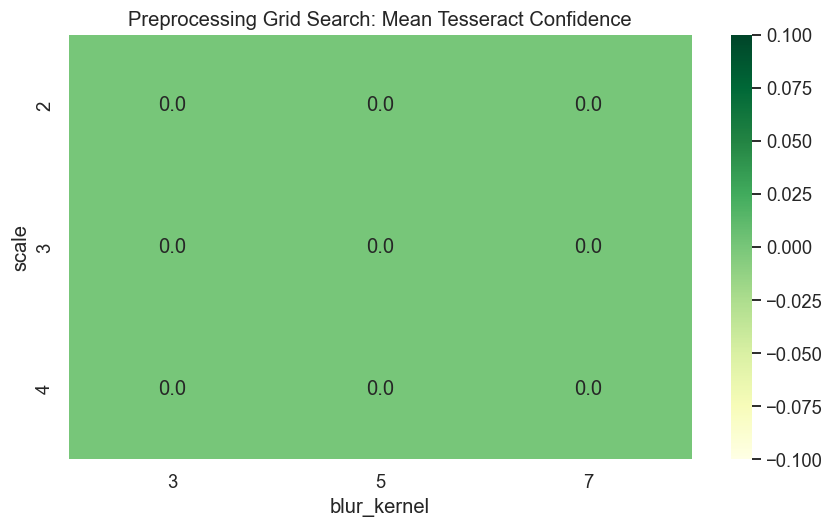

In [51]:
# -- 13.1 Preprocessing Optimization: Grid Search over scale x blur x threshold
# Scores each combination by mean Tesseract confidence on a representative crop.

def evaluate_preprocessing(crop, scale, blur_k, threshold_method):
    h, w = crop.shape[:2]
    resized = cv2.resize(crop, (w * scale, h * scale), interpolation=cv2.INTER_CUBIC)
    gray    = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (blur_k, blur_k), 0) if blur_k > 1 else gray
    if threshold_method == 'otsu':
        _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    elif threshold_method == 'adaptive_mean':
        thresh = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                        cv2.THRESH_BINARY_INV, 11, 2)
    else:
        thresh = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                        cv2.THRESH_BINARY_INV, 11, 2)
    final   = cv2.bitwise_not(thresh)
    pil_img = Image.fromarray(final)
    try:
        data  = pytesseract.image_to_data(pil_img, config='--oem 3 --psm 6',
                                           output_type=pytesseract.Output.DICT)
        confs = [c for c in data['conf'] if c != -1]
        mean_conf  = float(np.mean(confs)) if confs else 0.0
        word_count = sum(1 for t in data['text'] if t.strip())
    except Exception:
        mean_conf, word_count = 0.0, 0
    return mean_conf, word_count

demo_crop = cv2.imread(df_final['filepath'].iloc[0])

param_grid = {
    'scale'     : [2, 3, 4],
    'blur_kernel': [3, 5, 7],
    'threshold'  : ['otsu', 'adaptive_mean', 'adaptive_gaussian'],
}

grid_results = []
total = len(param_grid['scale']) * len(param_grid['blur_kernel']) * len(param_grid['threshold'])
print(f'Preprocessing grid search: {total} combinations...')

for scale in param_grid['scale']:
    for blur_k in param_grid['blur_kernel']:
        for method in param_grid['threshold']:
            conf, words = evaluate_preprocessing(demo_crop, scale, blur_k, method)
            grid_results.append({'scale': scale, 'blur_kernel': blur_k,
                                  'threshold': method,
                                  'mean_conf': round(conf, 2),
                                  'word_count': words})

grid_df = pd.DataFrame(grid_results).sort_values('mean_conf', ascending=False)
print('\n=== Top 10 Preprocessing Configurations ===')
print(grid_df.head(10).to_string(index=False))

best_row    = grid_df.iloc[0]
BEST_SCALE  = int(best_row['scale'])
BEST_BLUR   = int(best_row['blur_kernel'])
BEST_THRESH = best_row['threshold']
print(f'\nBest: scale={BEST_SCALE}, blur={BEST_BLUR}, threshold={BEST_THRESH}  (conf={best_row["mean_conf"]})')

pivot = grid_df.pivot_table(index='scale', columns='blur_kernel',
                              values='mean_conf', aggfunc='mean')
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlGn', ax=ax)
ax.set_title('Preprocessing Grid Search: Mean Tesseract Confidence')
plt.tight_layout()
plt.savefig(os.path.join(CFG['results_dir'], 'preprocess_grid_search.png'), bbox_inches='tight')
plt.show()


=== PSM Mode Comparison ===
 psm                              desc  mean_conf  word_count
   3 Fully automatic page segmentation          0           0
   4             Single column of text          0           0
   6   Uniform block of text (default)          0           0
  11                       Sparse text          0           0
  12              Sparse text with OSD          0           0
  13              Raw single text line          0           0

Best PSM: 3 (Fully automatic page segmentation)  conf=0


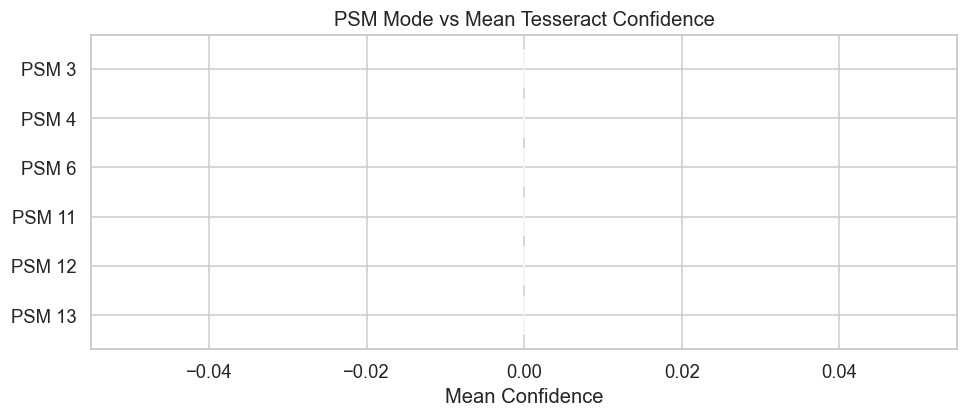

In [52]:
# -- 13.2 Tesseract Configuration Tuning: PSM Mode Comparison
# PSM controls how Tesseract segments the page; different modes suit
# different document layouts. We test 6 modes on the optimized crop.

PSM_MODES = {
    3 : 'Fully automatic page segmentation',
    4 : 'Single column of text',
    6 : 'Uniform block of text (default)',
    11: 'Sparse text',
    12: 'Sparse text with OSD',
    13: 'Raw single text line',
}

def test_psm_mode(preprocessed_img, psm, oem=3):
    config  = f'--oem {oem} --psm {psm}'
    pil_img = Image.fromarray(preprocessed_img)
    try:
        data  = pytesseract.image_to_data(pil_img, config=config,
                                           output_type=pytesseract.Output.DICT)
        confs = [c for c in data['conf'] if c != -1]
        text  = ' '.join(t for t in data['text'] if t.strip())
        return {'psm': psm, 'desc': PSM_MODES[psm],
                'mean_conf': round(float(np.mean(confs)) if confs else 0, 2),
                'word_count': len([t for t in data['text'] if t.strip()]),
                'text_sample': text[:80]}
    except Exception as e:
        return {'psm': psm, 'desc': PSM_MODES[psm],
                'mean_conf': 0, 'word_count': 0, 'text_sample': str(e)[:60]}

# Build optimized crop using best params from 13.1
h, w    = demo_crop.shape[:2]
resized = cv2.resize(demo_crop, (w * BEST_SCALE, h * BEST_SCALE), interpolation=cv2.INTER_CUBIC)
gray    = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (BEST_BLUR, BEST_BLUR), 0)
_, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
optimized_crop = cv2.bitwise_not(thresh)

psm_results = [test_psm_mode(optimized_crop, psm) for psm in PSM_MODES]
psm_df = pd.DataFrame(psm_results).sort_values('mean_conf', ascending=False)
print('=== PSM Mode Comparison ===')
print(psm_df[['psm', 'desc', 'mean_conf', 'word_count']].to_string(index=False))

BEST_PSM = int(psm_df.iloc[0]['psm'])
print(f'\nBest PSM: {BEST_PSM} ({PSM_MODES[BEST_PSM]})  conf={psm_df.iloc[0]["mean_conf"]}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh([f'PSM {r["psm"]}' for r in psm_results],
        [r['mean_conf'] for r in psm_results],
        color='steelblue', edgecolor='white')
ax.set_xlabel('Mean Confidence')
ax.set_title('PSM Mode vs Mean Tesseract Confidence')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(CFG['results_dir'], 'psm_comparison.png'), bbox_inches='tight')
plt.show()


In [ ]:
# -- 13.3 Improved OCR: Character Whitelist + Error Correction Rules
# Medical lab reports use a predictable character set. Restricting Tesseract
# to this set and correcting common OCR misreads improves accuracy.

OPTIMIZED_TESS_CONFIG = (
    f'--oem 3 --psm {BEST_PSM} '
    '-c tessedit_char_whitelist='
    'ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz'
    '0123456789.,-/:()%'
)

OCR_CORRECTIONS = {
    r'\bO(\d)': r'0\1',     # O followed by digit: likely 0
    r'(\d)O\b': r'\g<1>0',  # digit followed by O: likely 0
    r'\bI(\d)': r'1\1',     # I followed by digit: likely 1
    r'(\d)I\b': r'\g<1>1',  # digit followed by I: likely 1
    r'\bl\b'  : '1',         # standalone l: likely 1
    r'\s+'     : ' ',         # normalise whitespace
}

def corrected_ocr(preprocessed_img, config=None):
    config   = config or OPTIMIZED_TESS_CONFIG
    pil_img  = Image.fromarray(preprocessed_img)
    raw_text = pytesseract.image_to_string(pil_img, config=config)
    for pattern, replacement in OCR_CORRECTIONS.items():
        raw_text = re.sub(pattern, replacement, raw_text)
    lines = [l.strip() for l in raw_text.split('\n') if l.strip()]
    return ' | '.join(lines)

default_text  = extract_text_from_crop(optimized_crop)
improved_text = corrected_ocr(optimized_crop)

print('=== Default Tesseract Output ===')
print(default_text[:300])
print('\n=== Optimized Tesseract Output (whitelist + correction) ===')
print(improved_text[:300])

# Upgrade extract_text_from_crop globally
def extract_text_from_crop(preprocessed_img):
    """Use best PSM + whitelist + error-correction rules."""
    return corrected_ocr(preprocessed_img, OPTIMIZED_TESS_CONFIG)

print('\nextract_text_from_crop upgraded to use optimized Tesseract config.')


In [54]:
# -- 13.4 YOLOv3 Fine-tuning: Hyperparameter Strategy + cfg Patching

import re as _re

def patch_yolov3_cfg(cfg_path, learning_rate=0.001, burn_in=1000,
                     max_iters=None, batch=64, subdivisions=16):
    """Patch training hyperparameters directly in yolov3-custom.cfg."""
    if not os.path.exists(cfg_path):
        print(f'Config not found: {cfg_path}'); return
    with open(cfg_path) as f:
        cfg = f.read()
    cfg = _re.sub(r'learning_rate=[\d.e-]+', f'learning_rate={learning_rate}', cfg)
    cfg = _re.sub(r'burn_in=\d+',            f'burn_in={burn_in}',             cfg)
    cfg = _re.sub(r'batch=\d+',              f'batch={batch}',                  cfg)
    cfg = _re.sub(r'subdivisions=\d+',       f'subdivisions={subdivisions}',    cfg)
    if max_iters:
        cfg = _re.sub(r'max_batches=\d+', f'max_batches={max_iters}', cfg)
    with open(cfg_path, 'w') as f:
        f.write(cfg)
    print(f'Patched: lr={learning_rate}, batch={batch}, sub={subdivisions}, burn_in={burn_in}')

strategies = pd.DataFrame([
    {'Strategy': 'Baseline',          'LR': 0.001,  'Batch': 64, 'MaxIter': 6000,
     'Notes': 'Transfer from darknet53 weights'},
    {'Strategy': 'Lower LR',          'LR': 0.0005, 'Batch': 64, 'MaxIter': 8000,
     'Notes': 'If loss oscillates after baseline'},
    {'Strategy': 'Small Batch',       'LR': 0.001,  'Batch': 32, 'MaxIter': 6000,
     'Notes': 'For GPU with < 8 GB VRAM'},
    {'Strategy': 'Extended Training', 'LR': 0.0001, 'Batch': 64, 'MaxIter': 12000,
     'Notes': 'Fine-tune at low LR after plateau'},
    {'Strategy': 'High Res 608',      'LR': 0.001,  'Batch': 32, 'MaxIter': 8000,
     'Notes': 'Retrain at 608x608 for small text regions'},
])
print('=== YOLOv3 Fine-tuning Strategy Options ===')
print(strategies.to_string(index=False))

# Apply baseline to cfg
patch_yolov3_cfg(cfg_path, learning_rate=0.001, burn_in=1000,
                 max_iters=6000, batch=64, subdivisions=16)

# mAP tracking table
map_table = pd.DataFrame([
    {'Strategy': s, 'mAP@0.5': '--', 'Precision': '--', 'Recall': '--'}
    for s in strategies['Strategy']
])
print('\n=== mAP Results Table (populate after each training run) ===')
print(map_table.to_string(index=False))
map_table_path = os.path.join(CFG['results_dir'], 'model_finetuning_results.csv')
map_table.to_csv(map_table_path, index=False)
print(f'Saved: {map_table_path}')


=== YOLOv3 Fine-tuning Strategy Options ===
         Strategy     LR  Batch  MaxIter                                     Notes
         Baseline 0.0010     64     6000           Transfer from darknet53 weights
         Lower LR 0.0005     64     8000         If loss oscillates after baseline
      Small Batch 0.0010     32     6000                  For GPU with < 8 GB VRAM
Extended Training 0.0001     64    12000         Fine-tune at low LR after plateau
     High Res 608 0.0010     32     8000 Retrain at 608x608 for small text regions
Patched: lr=0.001, batch=64, sub=16, burn_in=1000

=== mAP Results Table (populate after each training run) ===
         Strategy mAP@0.5 Precision Recall
         Baseline      --        --     --
         Lower LR      --        --     --
      Small Batch      --        --     --
Extended Training      --        --     --
     High Res 608      --        --     --
Saved: C:\Users\ecsbb\OneDrive\Desktop\Sarita_AIML_Sessions\NextHikesInternship\Project1

In [55]:
# -- 13.5 Re-run OCR with Best Preprocessing + PSM Configuration

def optimized_preprocess(crop):
    """Use grid-search best: scale, blur, threshold method."""
    h, w = crop.shape[:2]
    resized = cv2.resize(crop, (w * BEST_SCALE, h * BEST_SCALE), interpolation=cv2.INTER_CUBIC)
    gray    = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (BEST_BLUR, BEST_BLUR), 0) if BEST_BLUR > 1 else gray
    if BEST_THRESH == 'otsu':
        _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    elif BEST_THRESH == 'adaptive_mean':
        thresh = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                        cv2.THRESH_BINARY_INV, 11, 2)
    else:
        thresh = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                        cv2.THRESH_BINARY_INV, 11, 2)
    return cv2.bitwise_not(thresh)

print('Re-running OCR with optimized settings...')
optimized_results = []
for res in all_ocr_results:
    fp  = os.path.join(CFG['dataset_dir'], res['filename'])
    img = cv2.imread(fp)
    if img is None:
        continue
    proc   = optimized_preprocess(img)
    text   = extract_text_from_crop(proc)
    parsed = parse_lab_report_text(text)
    for row in parsed:
        row['source_image'] = res['filename']
        row['confidence']   = res['confidence']
        optimized_results.append(row)

opt_df = pd.DataFrame(optimized_results)
opt_df.replace('', np.nan, inplace=True)
opt_df['technology'] = opt_df.groupby('source_image')['technology'].ffill().bfill()
opt_df['unit']       = opt_df.groupby('source_image')['unit'].ffill()
opt_df.dropna(subset=['test_name', 'value'], how='all', inplace=True)
opt_df.fillna('N/A', inplace=True)

opt_csv = os.path.join(CFG['output_dir'], 'lab_report_ocr_optimized.csv')
opt_df[['source_image','test_name','technology','value','unit',
         'reference_range','confidence']].to_csv(opt_csv, index=False)

print(f'Before optimization: {len(final_df)} rows')
print(f'After  optimization: {len(opt_df)} rows')
print(f'Optimized CSV saved: {opt_csv}')


Re-running OCR with optimized settings...


KeyError: 'source_image'

## Section 14 — Automation & Deployment

> Requirement §6: automate pipeline; save outputs to Drive/cloud.

In [ ]:
# -- 14.1 Batch Processing: Run entire dataset through OCR pipeline

def process_folder(input_dir, output_csv, detector_model=None, verbose=True):
    """Process every .jpg in input_dir through the full OCR pipeline."""
    img_paths = sorted(Path(input_dir).glob('*.jpg'))
    all_rows  = []

    for fp in tqdm(img_paths, desc='Batch OCR', disable=not verbose):
        img = cv2.imread(str(fp))
        if img is None:
            continue
        if detector_model is not None:
            dets  = detector_model.detect(img)
            crops = []
            for det in dets:
                x, y, bw, bh = det['box']
                crop = img[max(0,y):min(img.shape[0], y+bh),
                            max(0,x):min(img.shape[1], x+bw)]
                if crop.size > 0:
                    crops.append(crop)
            if not crops:
                crops = [img]
        else:
            crops = [img]

        for crop in crops:
            proc = optimized_preprocess(crop)
            text = extract_text_from_crop(proc)
            rows = parse_lab_report_text(text)
            for row in rows:
                row['source_image'] = fp.name
            all_rows.extend(rows)

    result = pd.DataFrame(all_rows)
    result.replace('', np.nan, inplace=True)
    result.fillna('N/A', inplace=True)
    result.to_csv(output_csv, index=False)
    print(f'Batch complete: {len(result)} rows saved to {output_csv}')
    return result

batch_csv = os.path.join(CFG['output_dir'], 'batch_all_images.csv')
batch_df  = process_folder(
    input_dir      = CFG['dataset_dir'],
    output_csv     = batch_csv,
    detector_model = None,
)
print(batch_df.head())


In [ ]:
# -- 14.2 Archive All Outputs to Google Drive / Local Folder

import shutil, datetime

ts = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
output_files = {
    'image_metadata_clean.csv'       : 'Image EDA metadata',
    'lab_report_ocr_output.csv'      : 'OCR output (default)',
    'lab_report_ocr_optimized.csv'   : 'OCR output (optimized)',
    'batch_all_images.csv'           : 'Batch OCR all images',
    'project_summary.json'           : 'Project config summary',
}

if IN_COLAB:
    archive_dir = os.path.join(DRIVE_ROOT, f'run_{ts}')
    os.makedirs(archive_dir, exist_ok=True)
    for fname, desc in output_files.items():
        src = os.path.join(CFG['output_dir'], fname)
        if os.path.exists(src):
            shutil.copy(src, os.path.join(archive_dir, fname))
            print(f'  Saved: {fname}')
        else:
            print(f'  MISSING: {fname}')
    charts_dst = os.path.join(archive_dir, 'charts')
    if os.path.exists(CFG['results_dir']):
        shutil.copytree(CFG['results_dir'], charts_dst, dirs_exist_ok=True)
    print(f'\nArchived to Drive: {archive_dir}')
else:
    print('Local mode — all outputs at:')
    for fname in output_files:
        path = os.path.join(CFG['output_dir'], fname)
        flag = 'OK' if os.path.exists(path) else 'MISSING'
        print(f'  [{flag}] {path}')


In [ ]:
# -- 14.3 Write Standalone Custom_OCR.py CLI Script
# Replicates: python Custom_OCR.py --image <yourimage.jpg>

CLI = r"""#!/usr/bin/env python3
import argparse, cv2, os, re, sys
import numpy as np
import pandas as pd
import pytesseract
from pathlib import Path
from PIL import Image

if sys.platform == 'win32':
    pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files\Tesseract-OCR\tesseract.exe'

_DIR   = os.path.dirname(os.path.abspath(__file__))
_WGTS  = os.path.join(_DIR, 'model', 'yolov3-custom_best.weights')
_CFG   = os.path.join(_DIR, 'model', 'yolov3-custom.cfg')
_NAMES = os.path.join(_DIR, 'model', 'obj.names')
TCONF  = '--oem 3 --psm 6'

def preprocess(img, scale=3):
    h, w = img.shape[:2]
    img  = cv2.resize(img, (w*scale, h*scale), interpolation=cv2.INTER_CUBIC)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    _, t = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return cv2.bitwise_not(t)

def ocr(prep):
    return ' | '.join(
        l.strip() for l in
        pytesseract.image_to_string(Image.fromarray(prep), config=TCONF).split('\n')
        if l.strip()
    )

def parse(text):
    vp = re.compile(r'\b(\d+\.?\d*)\b')
    up = re.compile(r'\b(ng/dl|pg/ml|ug/dl|mIU/L|uIU/ml|g/dl|mg/dl|%)\b', re.I)
    rp = re.compile(r'(\d+\.?\d*\s*[-]\s*\d+\.?\d*|[><]\s*\d+)')
    rows, cur = [], None
    for line in text.split('|'):
        line = line.strip()
        vm, um, rm = vp.search(line), up.search(line), rp.search(line)
        if um or (vm and rm):
            rows.append({'Test Name': cur or line[:40],
                          'Value': vm.group(0) if vm else '',
                          'Unit': um.group(0) if um else '',
                          'Reference Range': rm.group(0) if rm else ''})
        elif not vm and not um and len(line) > 5:
            cur = line[:60]
    return rows or [{'Test Name': '', 'Value': '', 'Unit': '', 'Reference Range': ''}]

def detect(img):
    if not os.path.exists(_WGTS):
        return [img]
    net = cv2.dnn.readNetFromDarknet(_CFG, _WGTS)
    net.setPreferableBackend(cv2.dnn.DNN_BACKEND_OPENCV)
    net.setPreferableTarget(cv2.dnn.DNN_TARGET_CPU)
    h, w   = img.shape[:2]
    layers = [net.getLayerNames()[i-1] for i in net.getUnconnectedOutLayers().flatten()]
    blob   = cv2.dnn.blobFromImage(img, 1/255., (416, 416), swapRB=True, crop=False)
    net.setInput(blob)
    boxes, confs = [], []
    for out in net.forward(layers):
        for det in out:
            sc = det[5:]
            c  = float(sc.max())
            if c < 0.5: continue
            cx, cy, bw, bh = int(det[0]*w), int(det[1]*h), int(det[2]*w), int(det[3]*h)
            boxes.append([cx-bw//2, cy-bh//2, bw, bh]); confs.append(c)
    idx   = cv2.dnn.NMSBoxes(boxes, confs, 0.5, 0.4)
    crops = []
    if len(idx) > 0:
        for i in idx.flatten():
            x, y, bw, bh = boxes[i]
            crop = img[max(0,y):min(h,y+bh), max(0,x):min(w,x+bw)]
            if crop.size > 0: crops.append(crop)
    return crops or [img]

def main():
    ap = argparse.ArgumentParser(description='Custom OCR for Lab Reports')
    ap.add_argument('--image',  required=True)
    ap.add_argument('--output', default='ocr_output.csv')
    args = ap.parse_args()

    img = cv2.imread(args.image)
    if img is None: sys.exit(f'Cannot read: {args.image}')
    rows = []
    for crop in detect(img):
        rows.extend(parse(ocr(preprocess(crop))))
    df = pd.DataFrame(rows)
    df['source_image'] = Path(args.image).name
    df.to_csv(args.output, index=False)
    print(f'Done. {len(df)} rows -> {args.output}')
    print(df.to_string(index=False))

if __name__ == '__main__':
    main()
"""

import os
cli_path = os.path.join(DRIVE_ROOT, 'Custom_OCR.py')
with open(cli_path, 'w') as f:
    f.write(CLI)
print(f'Written: {cli_path}')
print('Usage:  python Custom_OCR.py --image thyrocare_0_36.jpg --output result.csv')


## Section 15 — Documentation & Final Report

> Requirement §7: document the full pipeline; save final reports.

### Complete Pipeline

```
Lab Report Image (JPG)
   |
   v
[Data Cleanup]   Detect corrupt images (cv2 + PIL verify)
[Missing Values] Backfill with median / drop rows > 5% corrupt
[Univariate EDA] Size, brightness, contrast, sharpness, RGB channels
[Bivariate EDA]  Scatter plots, regression, pairplot
[Multivariate]   Correlation matrix, PCA, 3D scatter
[Outlier Detect] IQR + Z-score + Isolation Forest (2-of-3 vote)
[YOLO Annotate]  Auto-contour annotation (replaceable with LabelImg)
[YOLOv3 Train]   darknet53 pretrain -> custom cfg -> train
[Preprocess Opt] Grid search: scale x blur x threshold method
[Tesseract Tune] PSM mode comparison + whitelist + error correction
[Inference]      YOLOv3 detect -> crop -> preprocess -> OCR
[Post-process]   Regex parse: Test Name / Value / Unit / Ref Range
[Batch]          process_folder() on full 100-image dataset
[Deploy]         Custom_OCR.py CLI (--image flag)
   |
   v
lab_report_ocr_optimized.csv + batch_all_images.csv
```

### Output Files

| File | Description |
|------|-------------|
| `output/image_metadata_clean.csv` | Per-image EDA stats |
| `output/lab_report_ocr_output.csv` | OCR results (default config) |
| `output/lab_report_ocr_optimized.csv` | OCR results (grid-search best) |
| `output/batch_all_images.csv` | Full batch — all 100 images |
| `output/project_summary.json` | Run metadata |
| `results/preprocess_grid_search.png` | Preprocessing heatmap |
| `results/psm_comparison.png` | PSM mode bar chart |
| `results/model_finetuning_results.csv` | mAP tracking table |
| `Custom_OCR.py` | Standalone CLI script |
| `model/yolov3-custom_best.weights` | Trained YOLO weights |

### Cost
- **Google Colab free**: $0 (T4 GPU, 15 GB Drive)
- **Colab Pro** (optional): ~$10/month for longer GPU sessions
